# Air temperature projections

Multi-model CMIP6 projections prepared by CSIRO on a common 1° Pacific grid. Every model's annual series is averaged over each EEZ and over all the EEZs together (cosine-of-latitude weights) and expressed as the change relative to its own 2015–2035 mean. For each indicator:

* **Trend map** — linear trend over 2015–2100 of the multi-model median change in each EEZ, one panel per scenario.
* **Warming-level map** — multi-model median change in each EEZ in the year each scenario first reaches each global warming level, one figure per scenario on a shared colour scale.
* **All-EEZ box plots** — spread across models at each warming level for the mean over all the Pacific EEZs.

```{glue:figure} tas_fig
:scale: 60%
:align: center
```

**Figure. Change in mean temperature relative to 2015–2035 in each Pacific EEZ at the global warming levels** (multi-model median, `map_scenario`).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ and all-EEZ means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
sys.path.append("../../../../functions")
import projections as prj
import projections_regional as reg

### Configuration

Scenarios and global warming levels are the ones of the national projections ([`../../National/00_warming_levels.ipynb`](../../National/00_warming_levels.ipynb)). Maps of the change at warming levels are drawn for every scenario on a shared colour scale (`map_scenario` is the one shown at the top of the notebook); box plots show every scenario. Figures go to `outputs/figures/regional_pacific/PRJ_*` and tables to `outputs/tables/regional_pacific/PRJ_*`.

In [3]:
ssp_scenarios = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
map_scenario = "ssp370"
scenario_info = prj.load_warming_levels(ssp_scenarios)

eez = reg.load_eez()
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

## Mean temperature

Annual mean near-surface air temperature (°C).

**Mean temperature: linear trend 2015–2100 of the multi-model median (°C per decade), by EEZ**

,SSP126,SSP245,SSP370,SSP585
American Samoa,0.0603,0.1721,0.2912,0.3703
Cook Islands,0.0592,0.1740,0.2899,0.3722
Fiji,0.0536,0.1729,0.2941,0.3742
French Polynesia,0.0569,0.1618,0.2711,0.3552
Hawaii,0.0672,0.1933,0.3141,0.4313
Howland Island and Baker Island,0.0753,0.2116,0.3441,0.4397
Jarvis Island,0.0800,0.2212,0.3600,0.4657
Johnston Atoll,0.0647,0.1899,0.3158,0.4166
Kiribati,0.0701,0.2008,0.3213,0.4145
Line Group,0.0734,0.1991,0.3274,0.4221


**Change in mean temperature vs 2015–2035 at the global warming levels (SSP126, multi-model median, °C), by EEZ**

,+1.5°C (2032)
region,
American Samoa,0.100
Cook Islands,0.139
Fiji,0.181
French Polynesia,0.076
Hawaii,0.156
Howland Island and Baker Island,0.236
Jarvis Island,0.123
Johnston Atoll,0.226
Kiribati,0.264


**Change in mean temperature vs 2015–2035 at the global warming levels (SSP245, multi-model median, °C), by EEZ**

,+1.5°C (2030),+2.0°C (2052),+2.5°C (2079)
region,,,
American Samoa,0.081,0.619,0.959
Cook Islands,0.054,0.618,0.990
Fiji,0.117,0.552,1.037
French Polynesia,0.052,0.531,0.925
Hawaii,0.127,0.590,1.126
Howland Island and Baker Island,0.126,0.741,1.324
Jarvis Island,0.077,0.820,1.403
Johnston Atoll,0.172,0.560,1.139
Kiribati,0.159,0.743,1.231


... (2 outputs left out)

**Change in mean temperature vs 2015–2035 at the global warming levels (SSP585, multi-model median, °C), by EEZ**

,+1.5°C (2027),+2.0°C (2041),+2.5°C (2053),+3.0°C (2064)
region,,,,
American Samoa,0.070,0.513,0.901,1.386
Cook Islands,0.035,0.488,0.847,1.360
Fiji,0.074,0.506,0.809,1.335
French Polynesia,0.011,0.413,0.753,1.288
Hawaii,0.108,0.543,1.051,1.423
Howland Island and Baker Island,0.238,0.368,1.130,1.603
Jarvis Island,0.155,0.274,1.065,1.543
Johnston Atoll,0.109,0.511,0.898,1.385
Kiribati,0.149,0.490,1.051,1.559


**Change in mean temperature vs 2015–2035 at the global warming levels (°C): spread across models in All Pacific EEZs**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,All Pacific EEZs,SSP126,+1.5°C,2032,38,0.151,-0.043,0.252,-0.149,0.313
1,All Pacific EEZs,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,All Pacific EEZs,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,All Pacific EEZs,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,All Pacific EEZs,SSP245,+1.5°C,2030,38,0.109,-0.075,0.259,-0.285,0.317
5,All Pacific EEZs,SSP245,+2.0°C,2052,38,0.630,0.387,0.854,0.304,1.036
6,All Pacific EEZs,SSP245,+2.5°C,2079,38,1.108,0.655,1.390,0.490,1.623
7,All Pacific EEZs,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,All Pacific EEZs,SSP370,+1.5°C,2030,38,0.112,-0.096,0.247,-0.256,0.343
9,All Pacific EEZs,SSP370,+2.0°C,2046,38,0.529,0.379,0.779,0.276,0.877


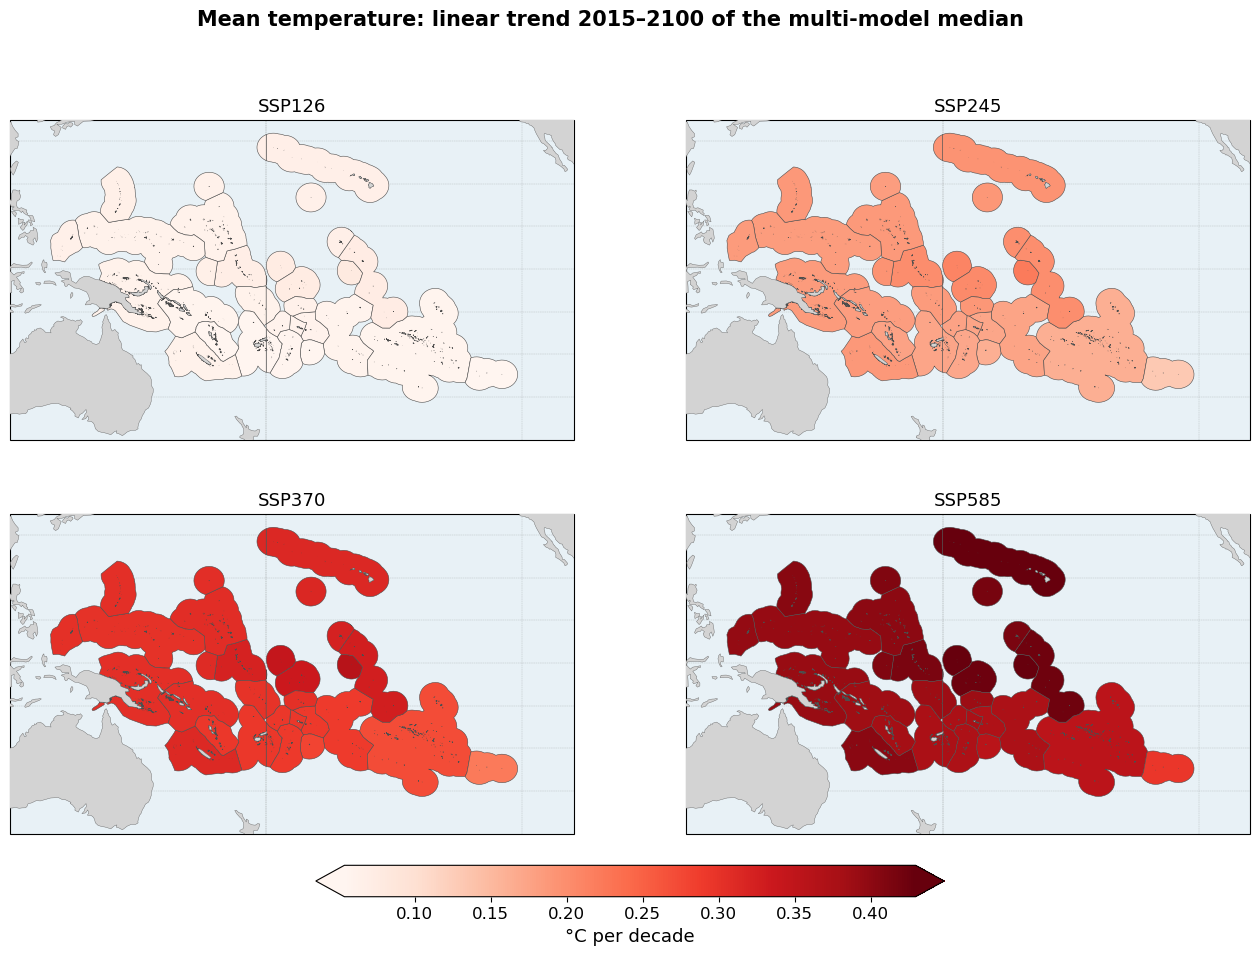

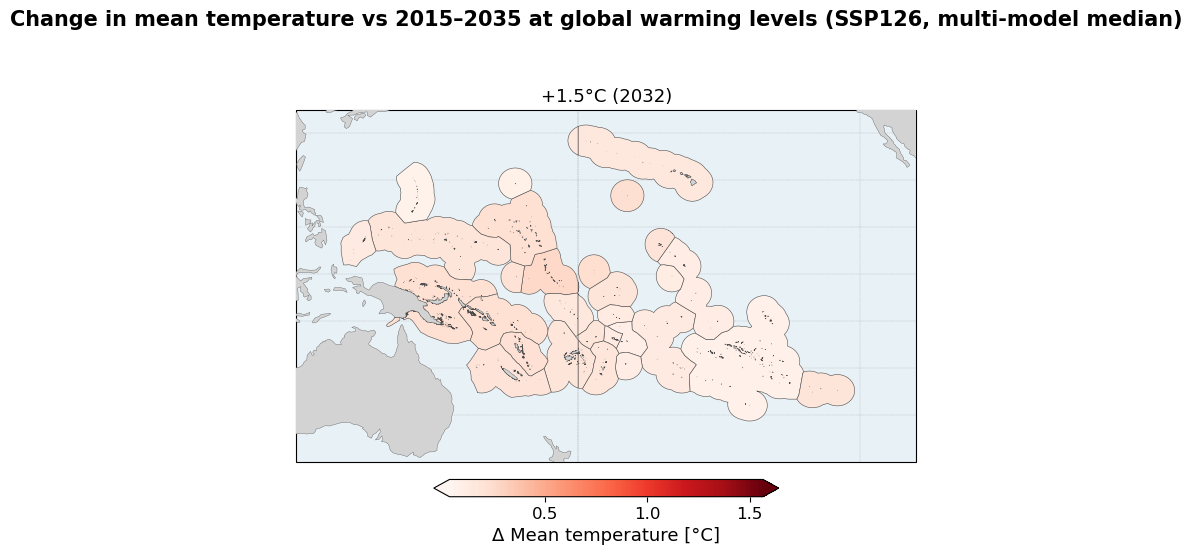

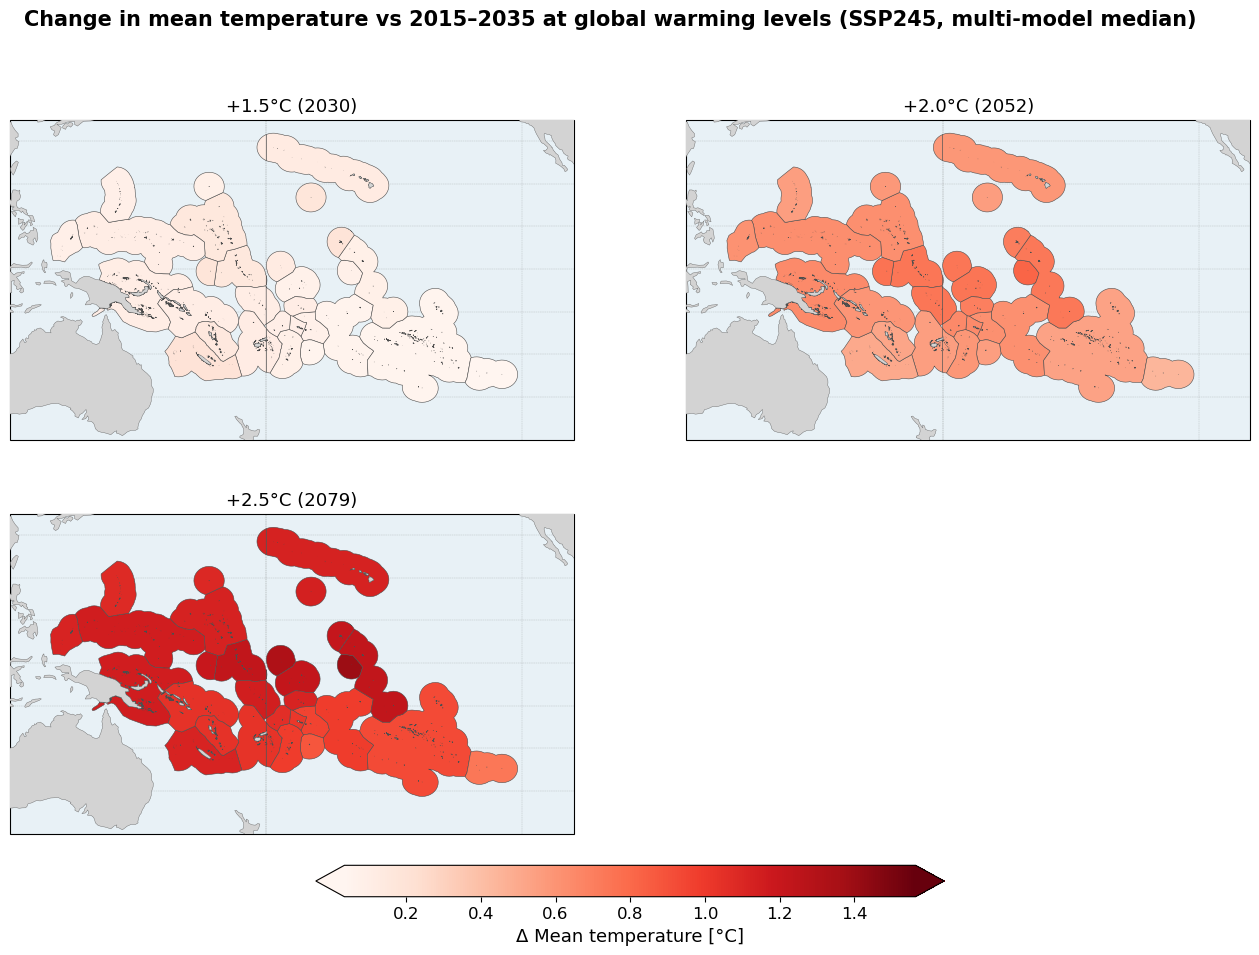

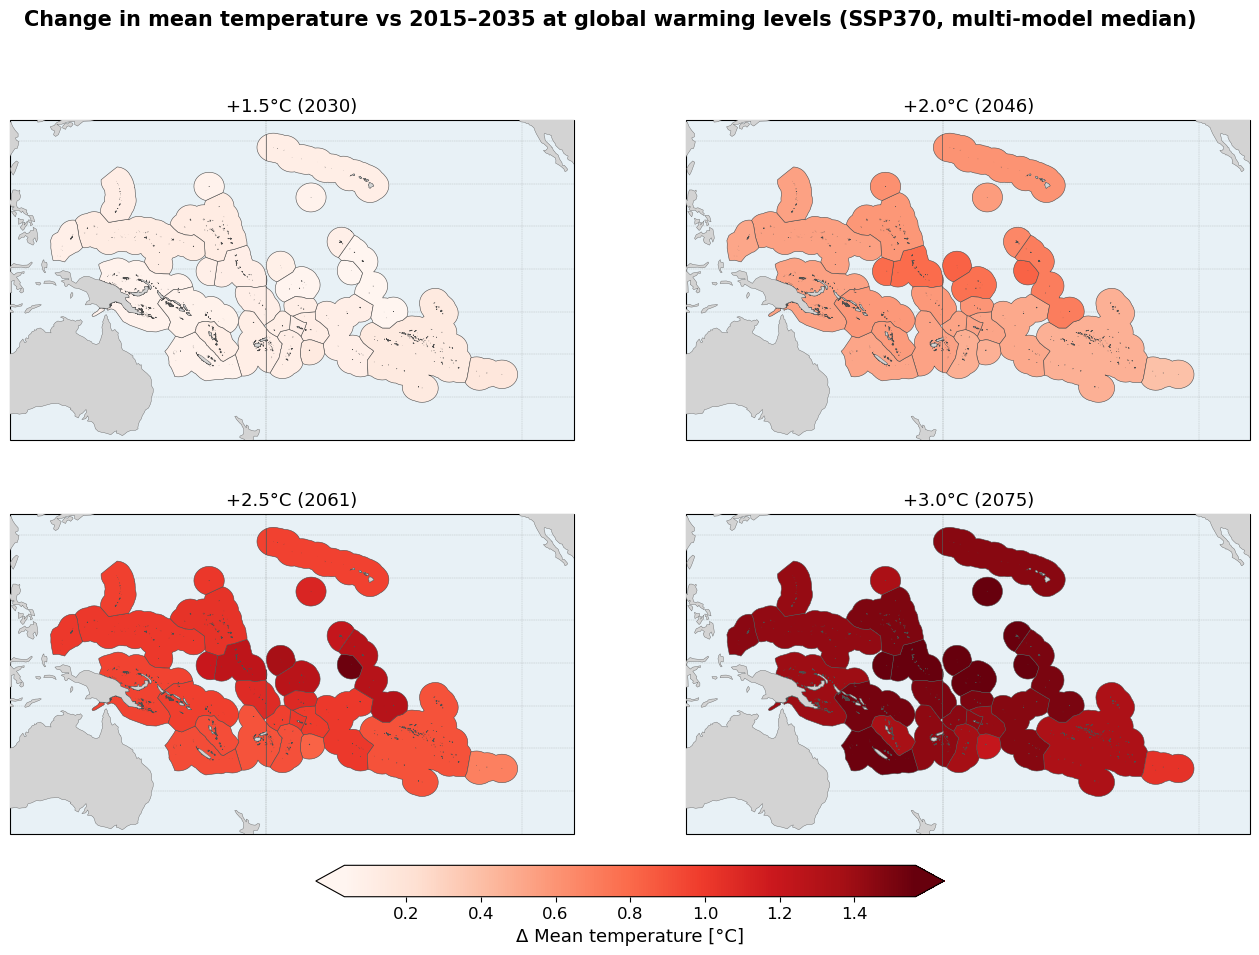

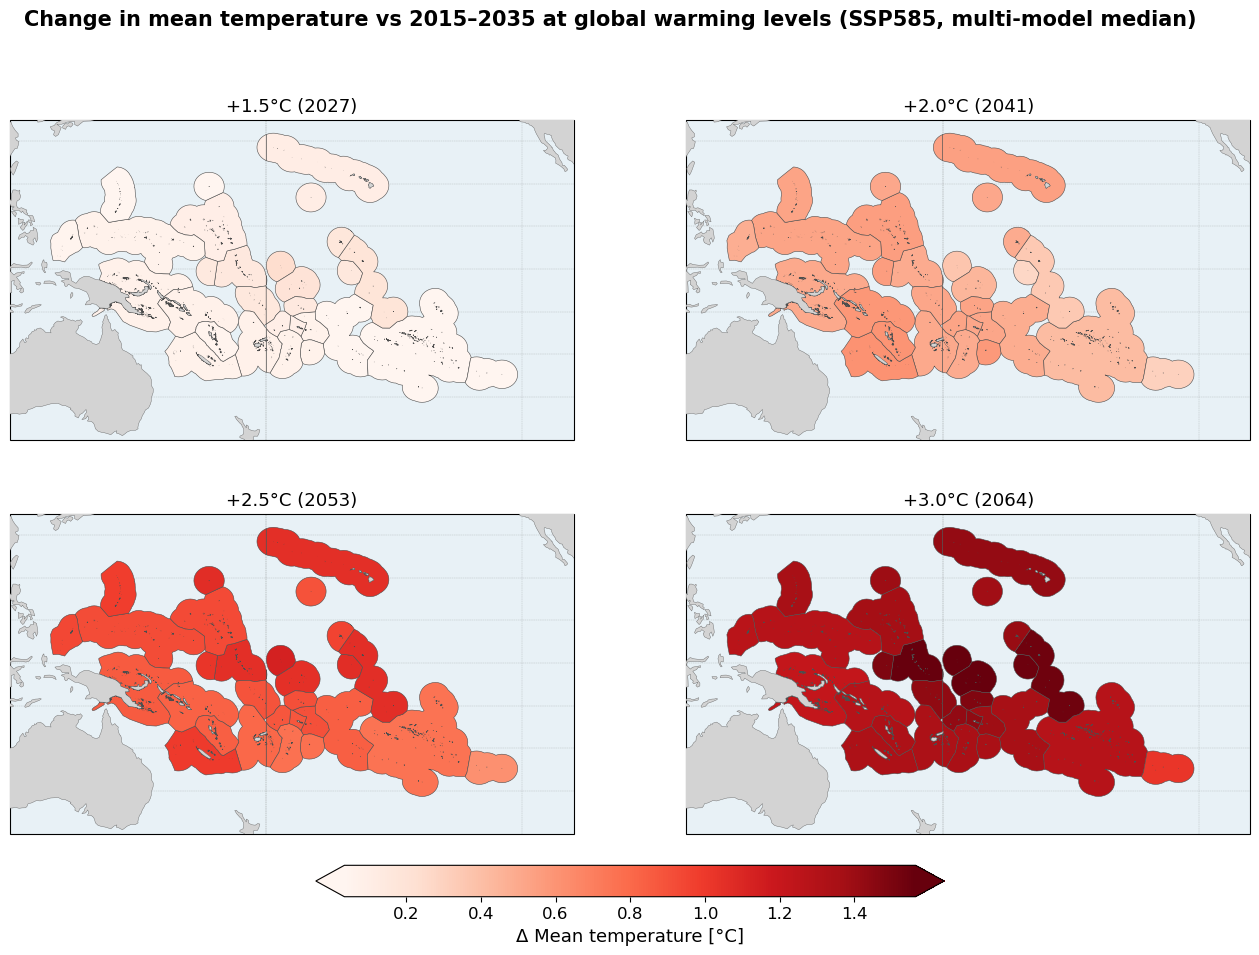

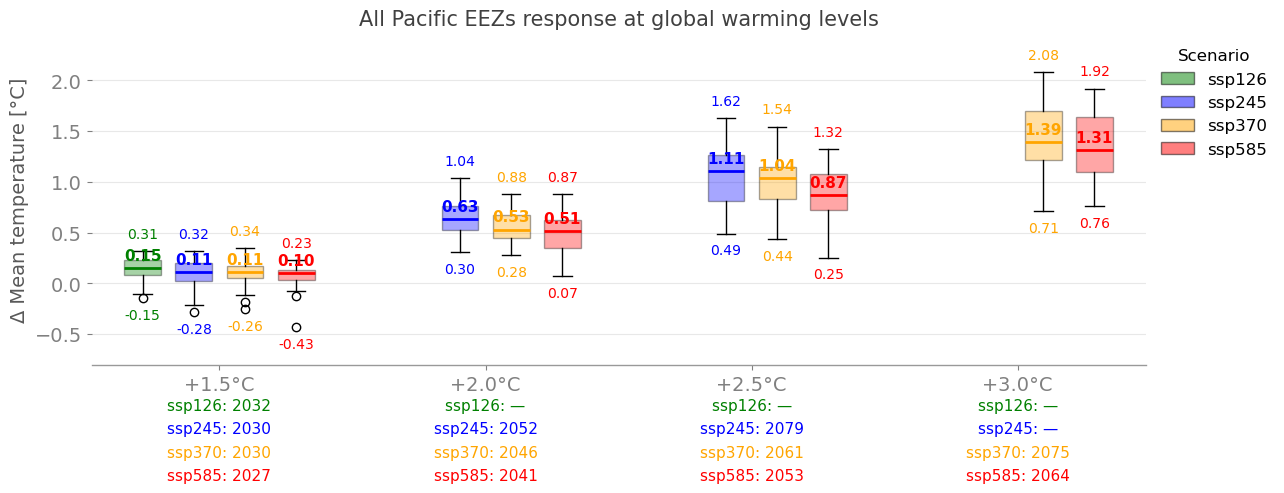

In [4]:
ds = reg.extract_regional_means("tas", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "tas", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
glue("tas_fig", figs["levels"], display=False)
reg.show_tables(tables)


## Minimum temperature

Annual minimum near-surface air temperature (°C).

**Minimum temperature: linear trend 2015–2100 of the multi-model median (°C per decade), by EEZ**

,SSP126,SSP245,SSP370,SSP585
American Samoa,0.0620,0.1780,0.3035,0.3905
Cook Islands,0.0596,0.1778,0.3033,0.3910
Fiji,0.0544,0.1789,0.3037,0.3882
French Polynesia,0.0562,0.1668,0.2845,0.3696
Hawaii,0.0751,0.1919,0.3265,0.4454
Howland Island and Baker Island,0.0726,0.1987,0.3396,0.4387
Jarvis Island,0.0816,0.2100,0.3548,0.4581
Johnston Atoll,0.0675,0.1923,0.3219,0.4285
Kiribati,0.0719,0.1925,0.3220,0.4237
Line Group,0.0696,0.1958,0.3305,0.4216


**Change in minimum temperature vs 2015–2035 at the global warming levels (SSP126, multi-model median, °C), by EEZ**

,+1.5°C (2032)
region,
American Samoa,0.066
Cook Islands,0.111
Fiji,0.190
French Polynesia,0.100
Hawaii,0.194
Howland Island and Baker Island,0.183
Jarvis Island,0.076
Johnston Atoll,0.268
Kiribati,0.158


**Change in minimum temperature vs 2015–2035 at the global warming levels (SSP245, multi-model median, °C), by EEZ**

,+1.5°C (2030),+2.0°C (2052),+2.5°C (2079)
region,,,
American Samoa,0.040,0.661,1.131
Cook Islands,0.051,0.617,1.111
Fiji,0.158,0.547,1.046
French Polynesia,0.026,0.516,1.011
Hawaii,0.118,0.641,1.222
Howland Island and Baker Island,0.166,0.716,1.280
Jarvis Island,0.144,0.658,1.238
Johnston Atoll,0.170,0.636,1.190
Kiribati,0.180,0.675,1.212


... (2 outputs left out)

**Change in minimum temperature vs 2015–2035 at the global warming levels (SSP585, multi-model median, °C), by EEZ**

,+1.5°C (2027),+2.0°C (2041),+2.5°C (2053),+3.0°C (2064)
region,,,,
American Samoa,0.076,0.461,0.858,1.379
Cook Islands,0.031,0.441,0.816,1.314
Fiji,0.101,0.507,0.844,1.357
French Polynesia,0.046,0.384,0.810,1.291
Hawaii,0.213,0.593,1.020,1.429
Howland Island and Baker Island,0.222,0.327,1.072,1.489
Jarvis Island,0.176,0.268,1.050,1.574
Johnston Atoll,0.148,0.572,0.865,1.435
Kiribati,0.123,0.491,1.021,1.473


**Change in minimum temperature vs 2015–2035 at the global warming levels (°C): spread across models in All Pacific EEZs**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,All Pacific EEZs,SSP126,+1.5°C,2032,27,0.173,-0.055,0.260,-0.135,0.308
1,All Pacific EEZs,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,All Pacific EEZs,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,All Pacific EEZs,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,All Pacific EEZs,SSP245,+1.5°C,2030,27,0.127,-0.071,0.231,-0.269,0.274
5,All Pacific EEZs,SSP245,+2.0°C,2052,27,0.614,0.381,0.868,0.308,1.017
6,All Pacific EEZs,SSP245,+2.5°C,2079,27,1.144,0.624,1.396,0.491,1.475
7,All Pacific EEZs,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,All Pacific EEZs,SSP370,+1.5°C,2030,27,0.111,-0.094,0.238,-0.246,0.343
9,All Pacific EEZs,SSP370,+2.0°C,2046,27,0.571,0.419,0.766,0.276,0.862


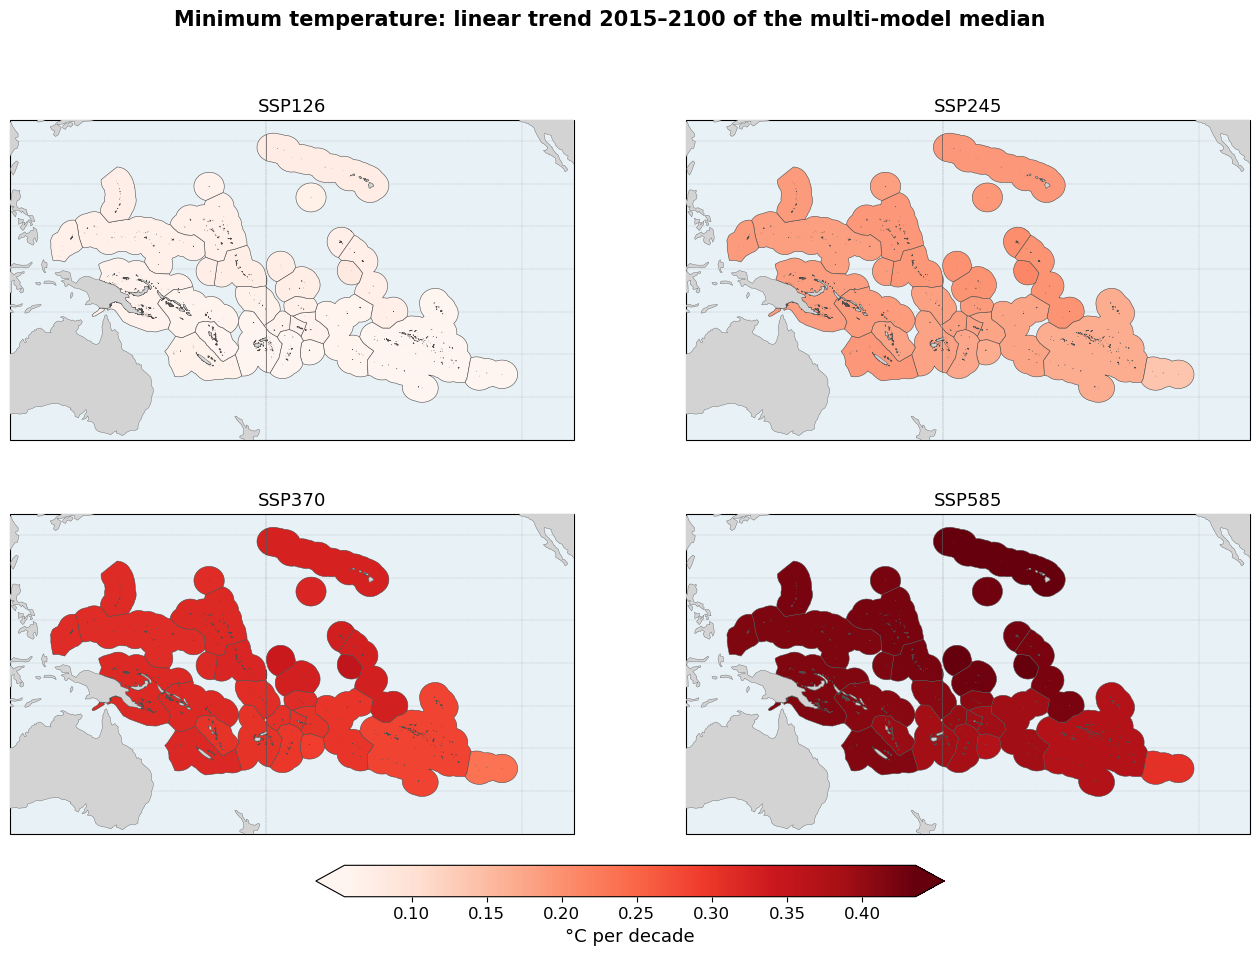

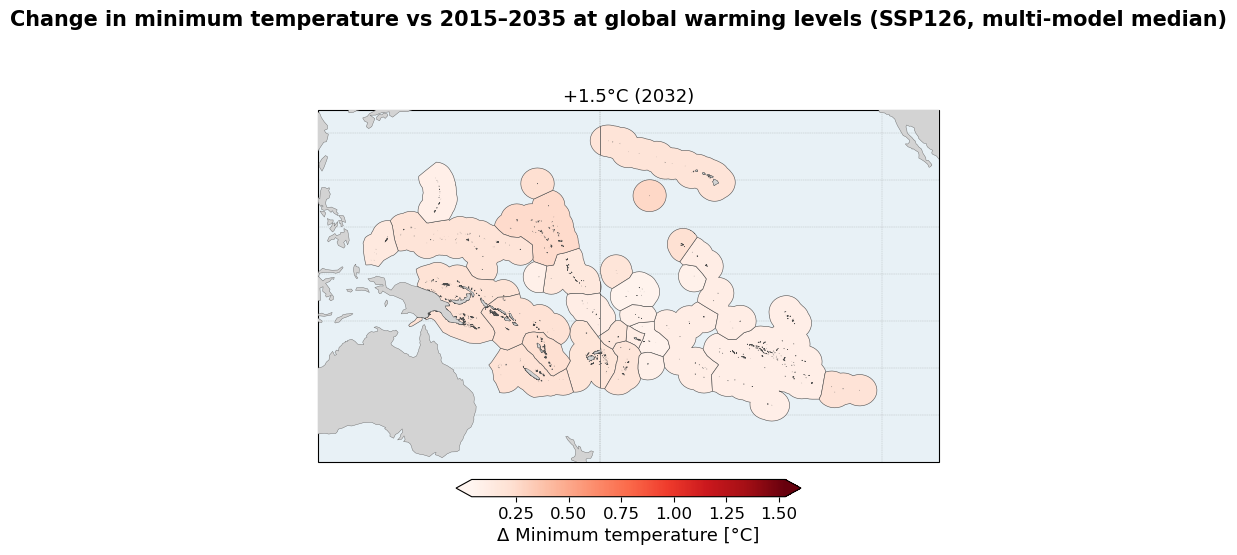

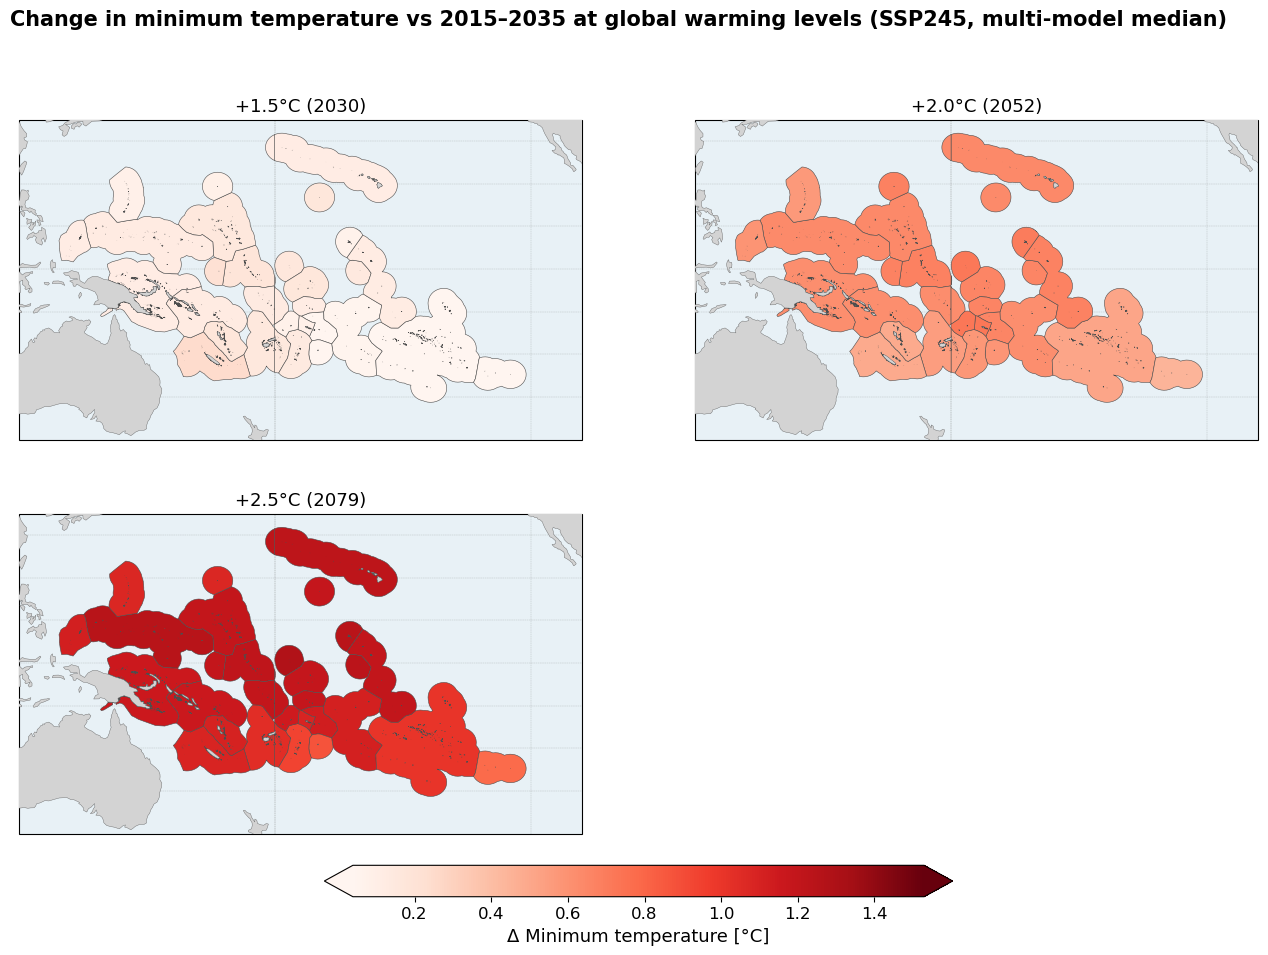

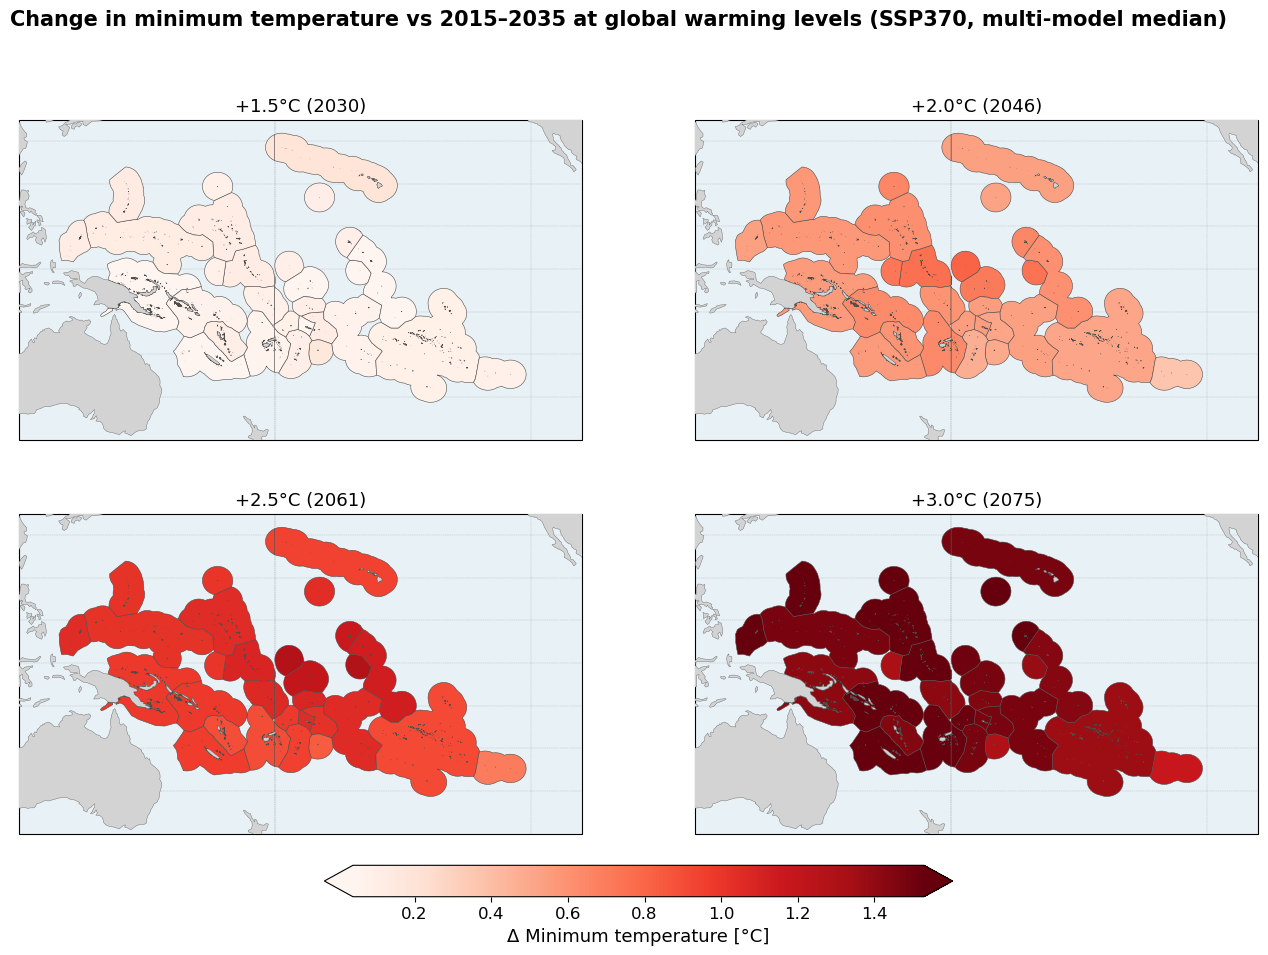

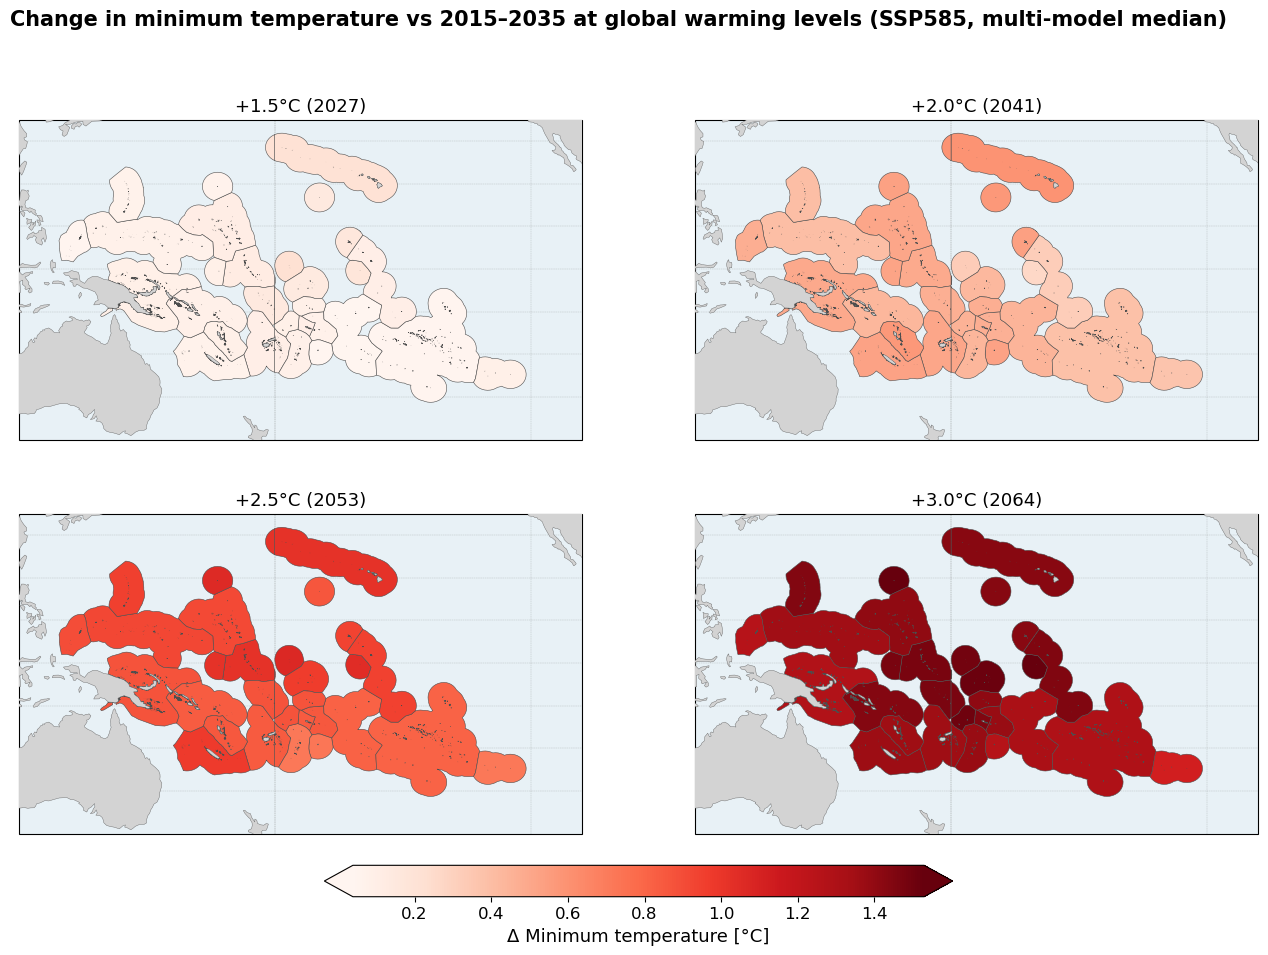

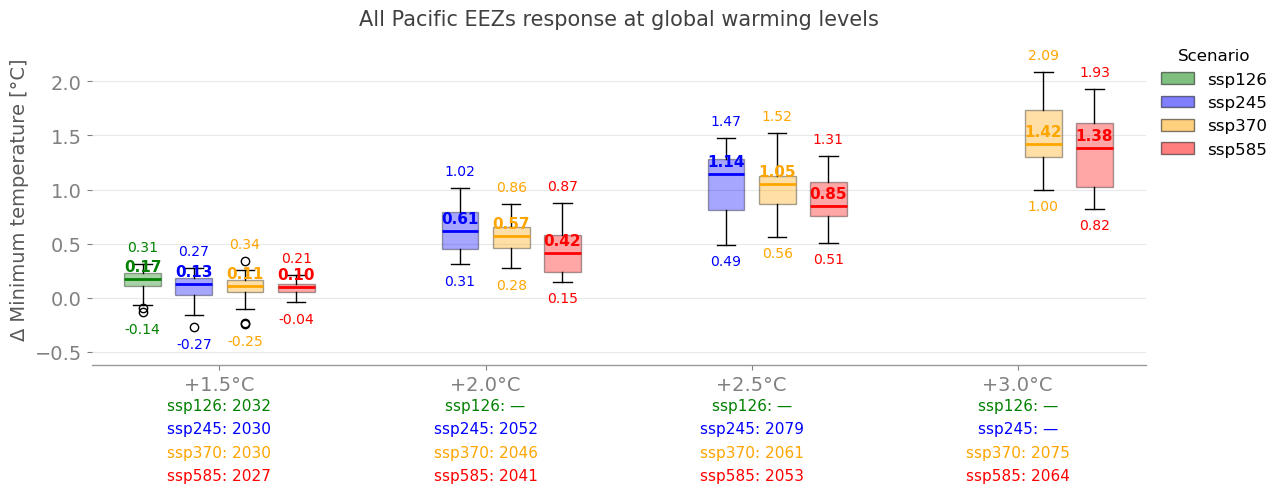

In [5]:
ds = reg.extract_regional_means("tasmin", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "tasmin", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
reg.show_tables(tables)


## Maximum temperature

Annual maximum near-surface air temperature (°C).

**Maximum temperature: linear trend 2015–2100 of the multi-model median (°C per decade), by EEZ**

,SSP126,SSP245,SSP370,SSP585
American Samoa,0.0621,0.1749,0.3015,0.3862
Cook Islands,0.0603,0.1749,0.2988,0.3843
Fiji,0.0527,0.1751,0.3000,0.3853
French Polynesia,0.0539,0.1620,0.2751,0.3584
Hawaii,0.0729,0.1912,0.3190,0.4388
Howland Island and Baker Island,0.0771,0.2045,0.3569,0.4518
Jarvis Island,0.0815,0.2137,0.3616,0.4643
Johnston Atoll,0.0694,0.1945,0.3211,0.4285
Kiribati,0.0759,0.1968,0.3348,0.4318
Line Group,0.0692,0.1959,0.3294,0.4230


**Change in maximum temperature vs 2015–2035 at the global warming levels (SSP126, multi-model median, °C), by EEZ**

,+1.5°C (2032)
region,
American Samoa,0.084
Cook Islands,0.092
Fiji,0.194
French Polynesia,0.112
Hawaii,0.199
Howland Island and Baker Island,0.128
Jarvis Island,-0.003
Johnston Atoll,0.226
Kiribati,0.198


**Change in maximum temperature vs 2015–2035 at the global warming levels (SSP245, multi-model median, °C), by EEZ**

,+1.5°C (2030),+2.0°C (2052),+2.5°C (2079)
region,,,
American Samoa,0.075,0.654,1.123
Cook Islands,0.080,0.596,1.054
Fiji,0.173,0.558,0.973
French Polynesia,0.004,0.524,0.974
Hawaii,0.094,0.626,1.157
Howland Island and Baker Island,0.187,0.745,1.358
Jarvis Island,0.149,0.737,1.224
Johnston Atoll,0.134,0.640,1.209
Kiribati,0.191,0.719,1.326


... (2 outputs left out)

**Change in maximum temperature vs 2015–2035 at the global warming levels (SSP585, multi-model median, °C), by EEZ**

,+1.5°C (2027),+2.0°C (2041),+2.5°C (2053),+3.0°C (2064)
region,,,,
American Samoa,0.095,0.482,0.883,1.384
Cook Islands,0.032,0.440,0.810,1.280
Fiji,0.067,0.518,0.809,1.300
French Polynesia,0.017,0.395,0.788,1.267
Hawaii,0.195,0.560,0.987,1.408
Howland Island and Baker Island,0.227,0.311,0.984,1.506
Jarvis Island,0.142,0.255,0.997,1.477
Johnston Atoll,0.151,0.580,0.852,1.402
Kiribati,0.126,0.460,1.003,1.475


**Change in maximum temperature vs 2015–2035 at the global warming levels (°C): spread across models in All Pacific EEZs**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,All Pacific EEZs,SSP126,+1.5°C,2032,27,0.171,-0.076,0.256,-0.164,0.310
1,All Pacific EEZs,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,All Pacific EEZs,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,All Pacific EEZs,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,All Pacific EEZs,SSP245,+1.5°C,2030,27,0.105,-0.084,0.237,-0.302,0.289
5,All Pacific EEZs,SSP245,+2.0°C,2052,27,0.566,0.389,0.877,0.300,1.052
6,All Pacific EEZs,SSP245,+2.5°C,2079,27,1.101,0.619,1.435,0.490,1.477
7,All Pacific EEZs,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,All Pacific EEZs,SSP370,+1.5°C,2030,27,0.109,-0.101,0.245,-0.265,0.344
9,All Pacific EEZs,SSP370,+2.0°C,2046,27,0.529,0.403,0.763,0.276,0.867


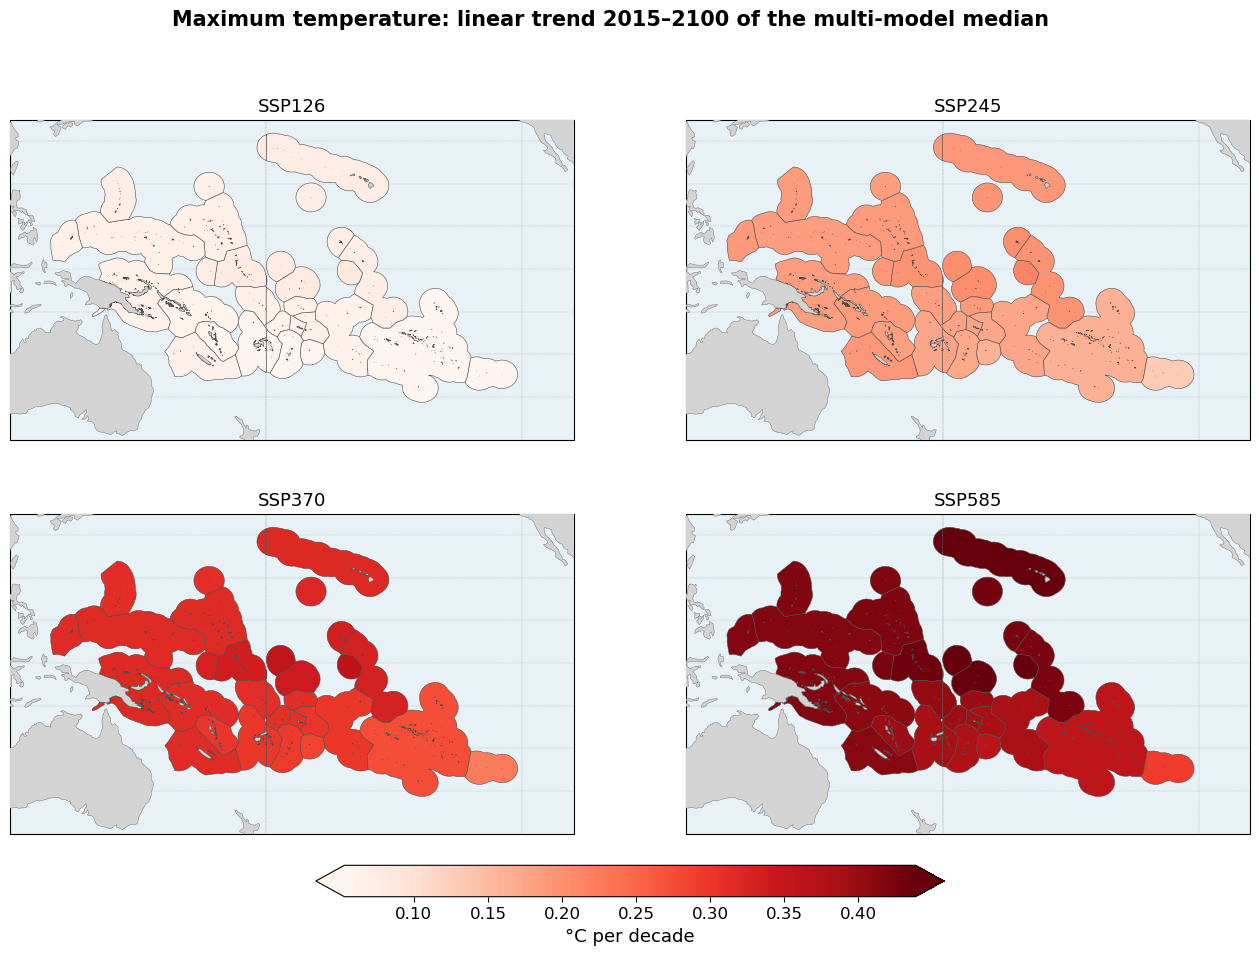

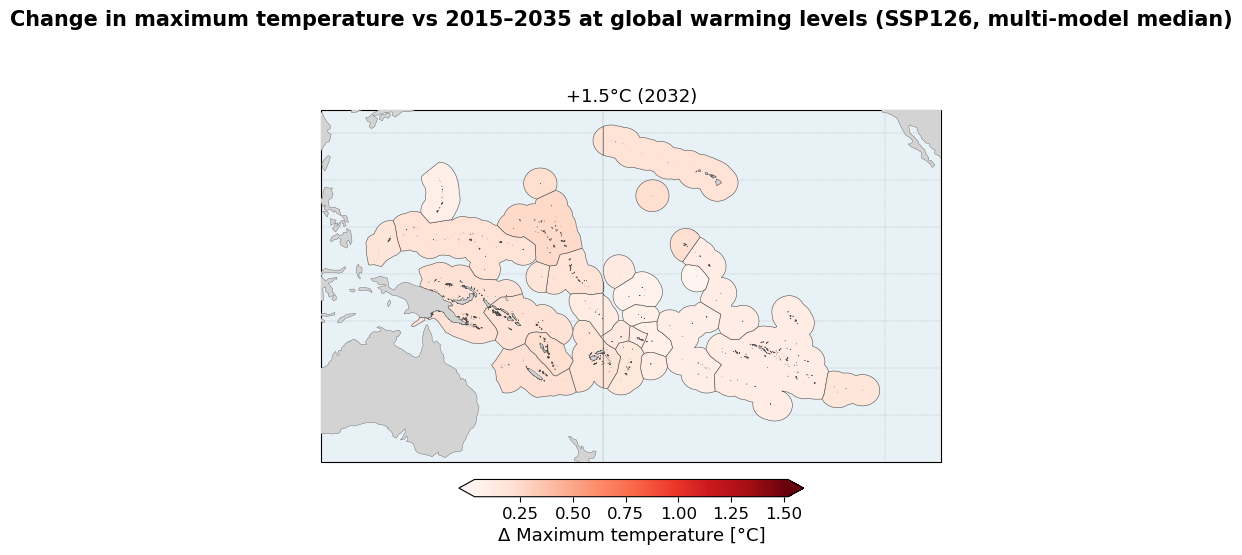

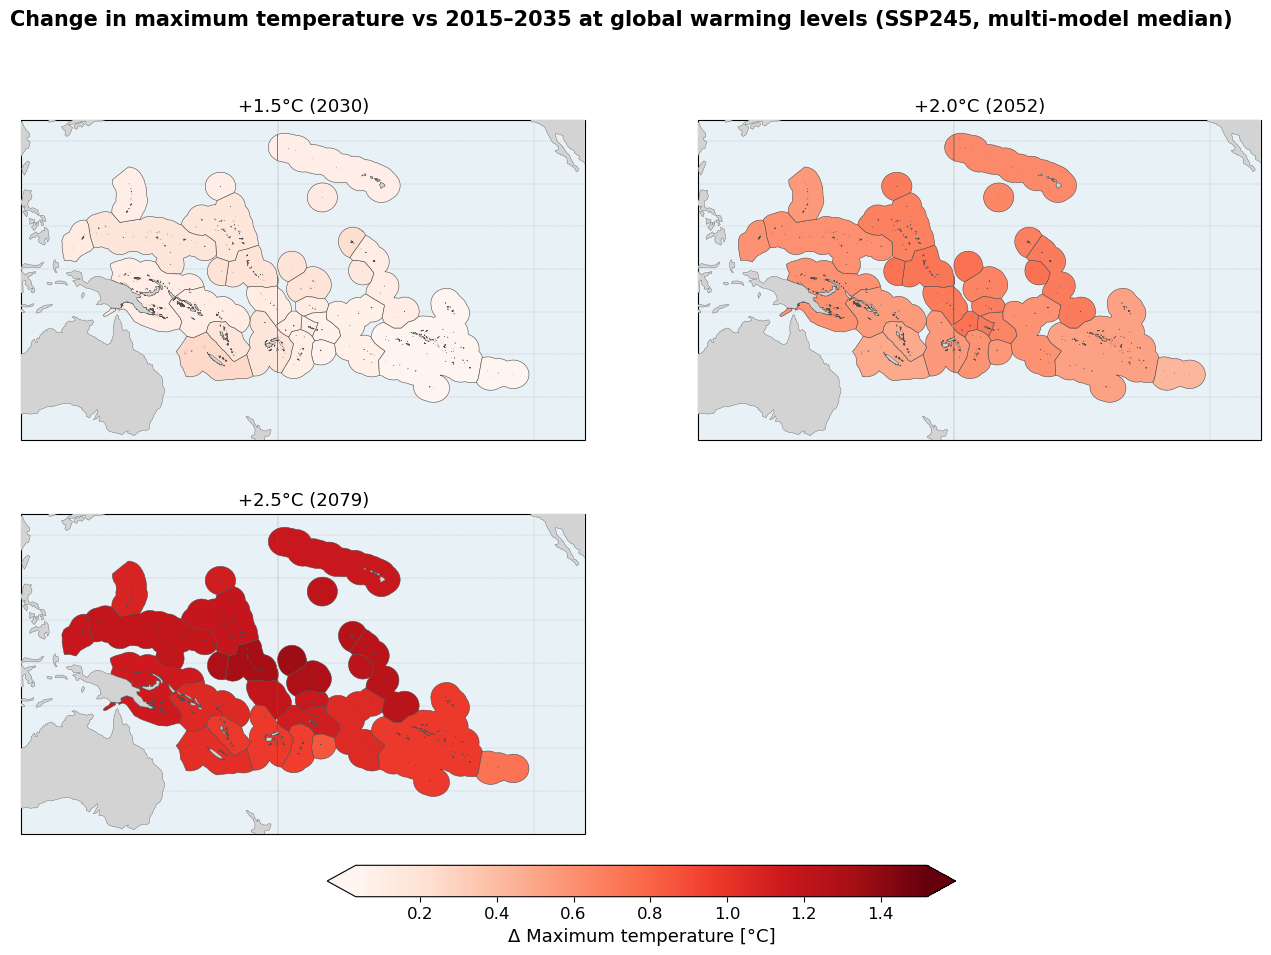

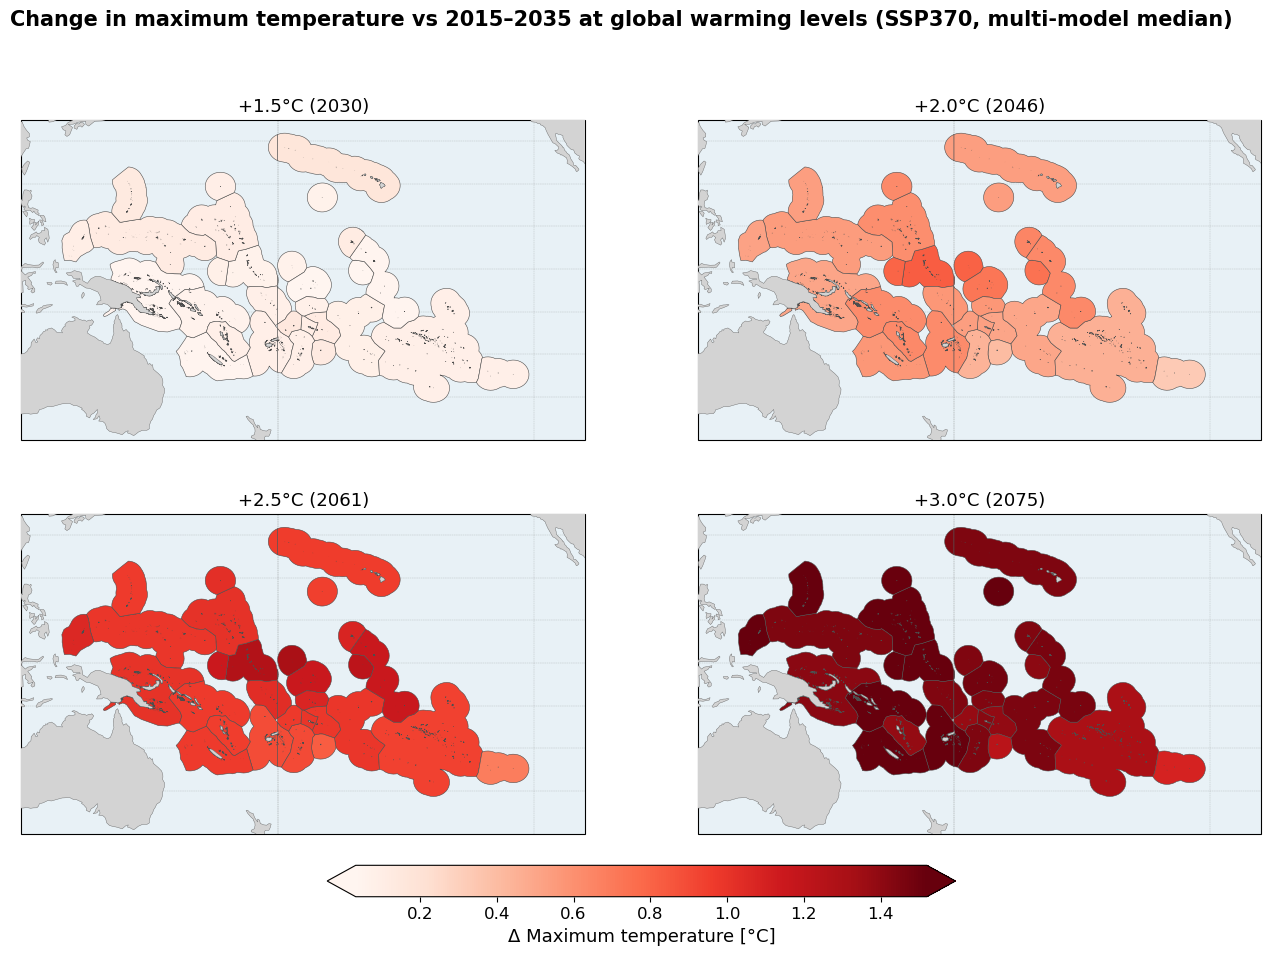

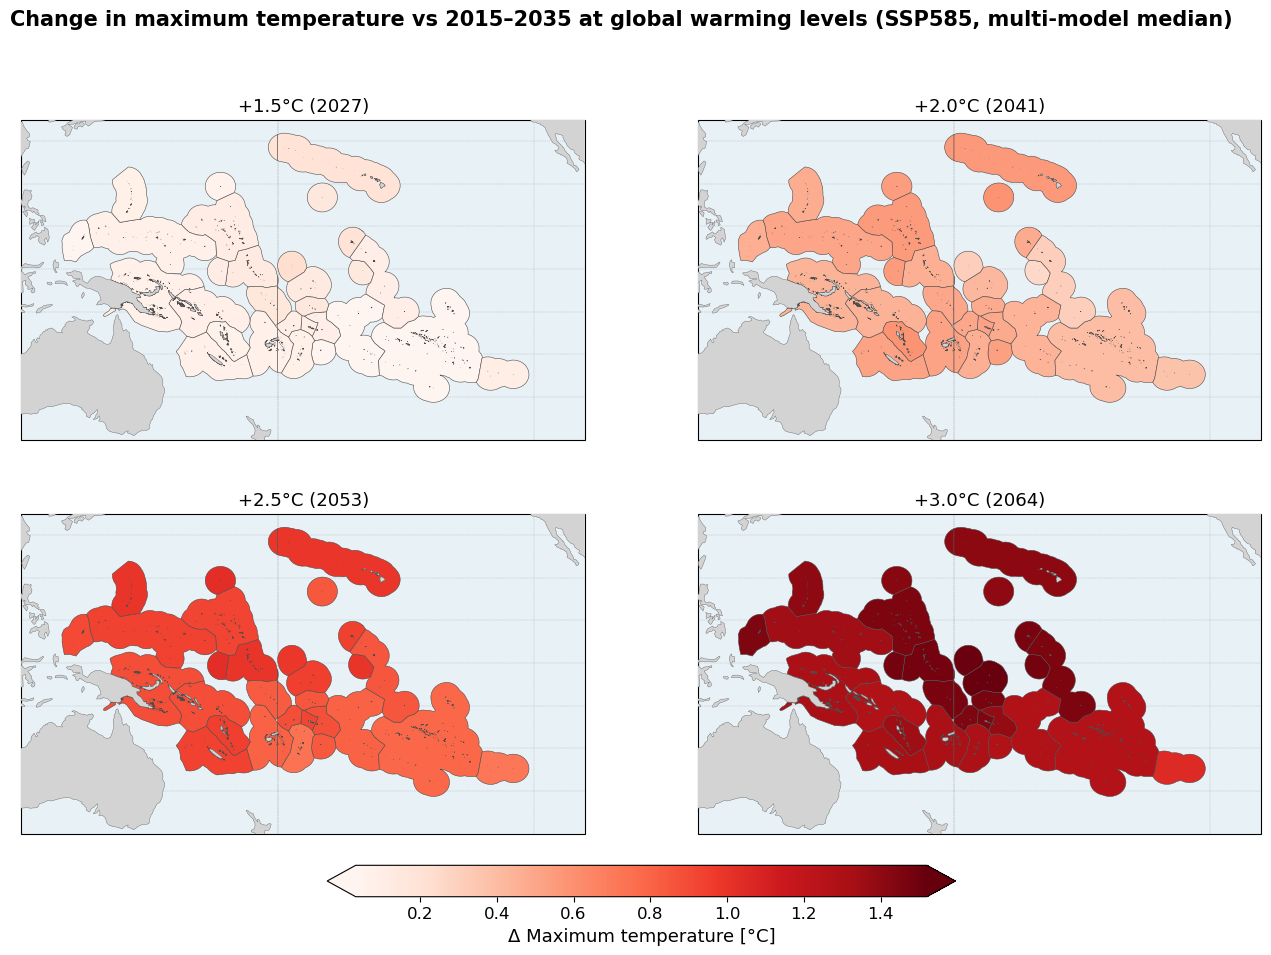

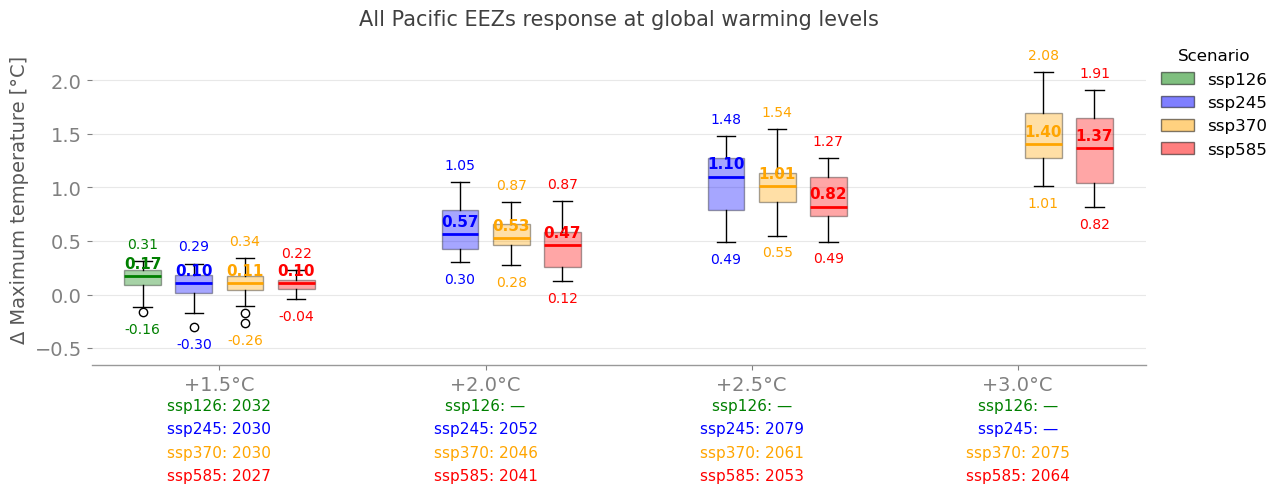

In [6]:
ds = reg.extract_regional_means("tasmax", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "tasmax", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
reg.show_tables(tables)


## Warm days

Annual number of warm days.

**Warm days: linear trend 2015–2100 of the multi-model median (days/year per decade), by EEZ**

,SSP126,SSP245,SSP370,SSP585
American Samoa,6.22,19.83,28.84,30.65
Cook Islands,6.88,17.67,23.65,25.44
Fiji,3.94,12.55,19.86,23.01
French Polynesia,4.36,13.10,19.43,22.72
Hawaii,3.86,10.15,16.63,20.42
Howland Island and Baker Island,9.83,24.00,27.90,30.34
Jarvis Island,8.69,23.08,28.89,31.49
Johnston Atoll,4.85,15.42,26.38,29.96
Kiribati,10.81,23.54,26.41,27.47
Line Group,9.71,23.64,28.38,29.61


**Change in warm days vs 2015–2035 at the global warming levels (SSP126, multi-model median, days/year), by EEZ**

,+1.5°C (2032)
region,
American Samoa,11.5
Cook Islands,13.3
Fiji,13.9
French Polynesia,8.4
Hawaii,10.1
Howland Island and Baker Island,7.5
Jarvis Island,-25.6
Johnston Atoll,15.6
Kiribati,30.2


**Change in warm days vs 2015–2035 at the global warming levels (SSP245, multi-model median, days/year), by EEZ**

,+1.5°C (2030),+2.0°C (2052),+2.5°C (2079)
region,,,
American Samoa,12.0,82.3,120.7
Cook Islands,4.2,75.6,101.0
Fiji,11.0,41.0,75.4
French Polynesia,2.5,47.7,75.2
Hawaii,-4.3,37.1,60.7
Howland Island and Baker Island,4.8,118.2,128.0
Jarvis Island,-22.6,103.8,95.3
Johnston Atoll,12.5,51.9,91.7
Kiribati,9.8,105.1,137.4


... (2 outputs left out)

**Change in warm days vs 2015–2035 at the global warming levels (SSP585, multi-model median, days/year), by EEZ**

,+1.5°C (2027),+2.0°C (2041),+2.5°C (2053),+3.0°C (2064)
region,,,,
American Samoa,17.4,57.5,106.4,151.0
Cook Islands,10.7,53.7,90.4,126.9
Fiji,3.8,31.6,65.7,96.1
French Polynesia,10.7,33.0,62.8,95.9
Hawaii,7.4,34.3,53.1,75.1
Howland Island and Baker Island,31.6,52.1,139.0,162.4
Jarvis Island,18.7,33.0,141.2,167.9
Johnston Atoll,8.9,49.8,82.4,104.1
Kiribati,24.6,89.0,139.1,153.1


**Change in warm days vs 2015–2035 at the global warming levels (days/year): spread across models in All Pacific EEZs**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,All Pacific EEZs,SSP126,+1.5°C,2032,26,20.8,-12.7,42.9,-39.2,48.0
1,All Pacific EEZs,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,All Pacific EEZs,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,All Pacific EEZs,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,All Pacific EEZs,SSP245,+1.5°C,2030,27,15.8,-17.1,33.6,-58.8,61.8
5,All Pacific EEZs,SSP245,+2.0°C,2052,27,75.2,44.7,89.2,25.9,118.3
6,All Pacific EEZs,SSP245,+2.5°C,2079,27,95.7,77.9,123.7,40.3,151.7
7,All Pacific EEZs,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,All Pacific EEZs,SSP370,+1.5°C,2030,27,8.3,-33.6,33.8,-56.3,49.1
9,All Pacific EEZs,SSP370,+2.0°C,2046,26,68.9,39.9,89.2,19.5,106.9


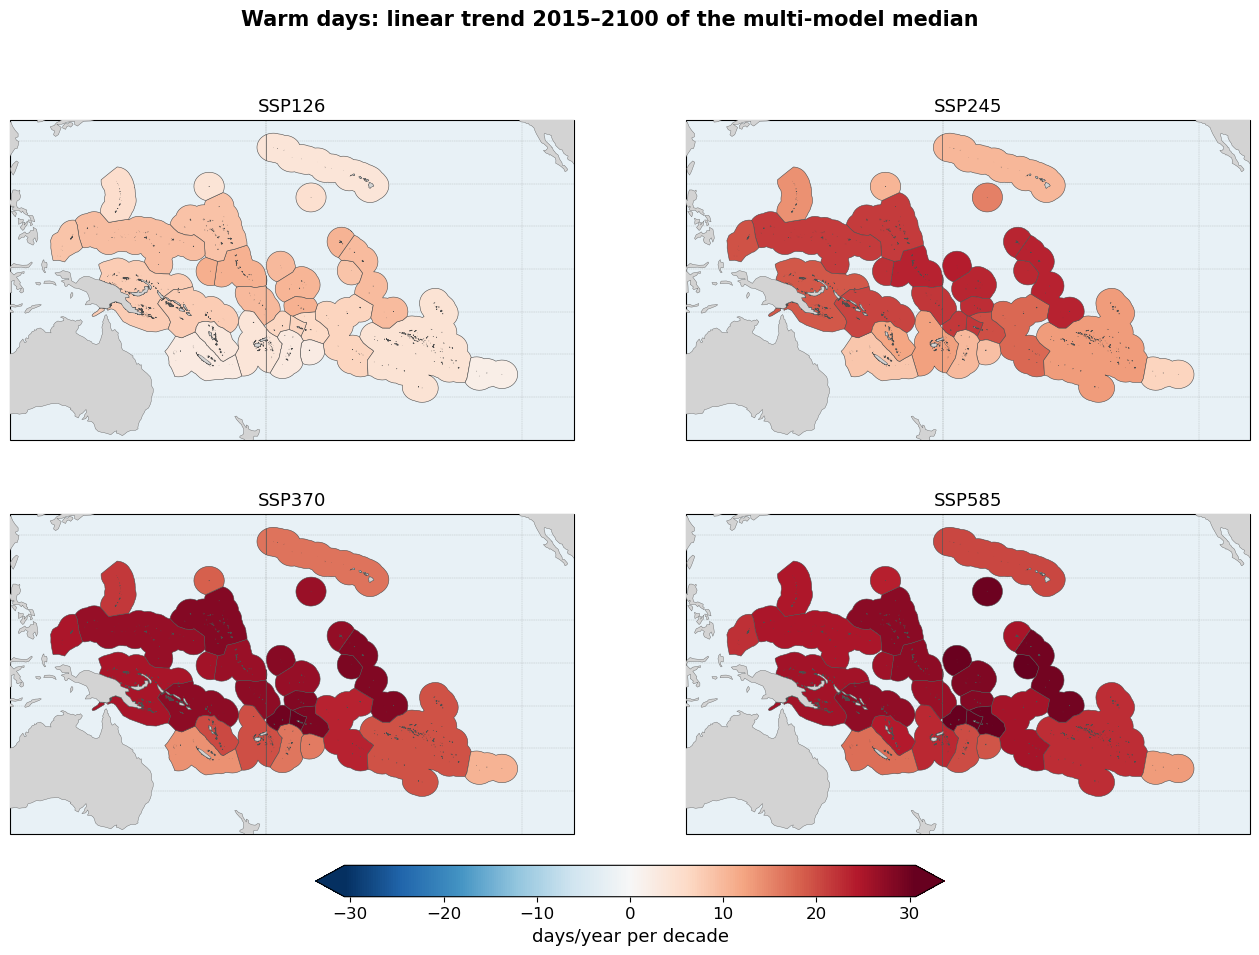

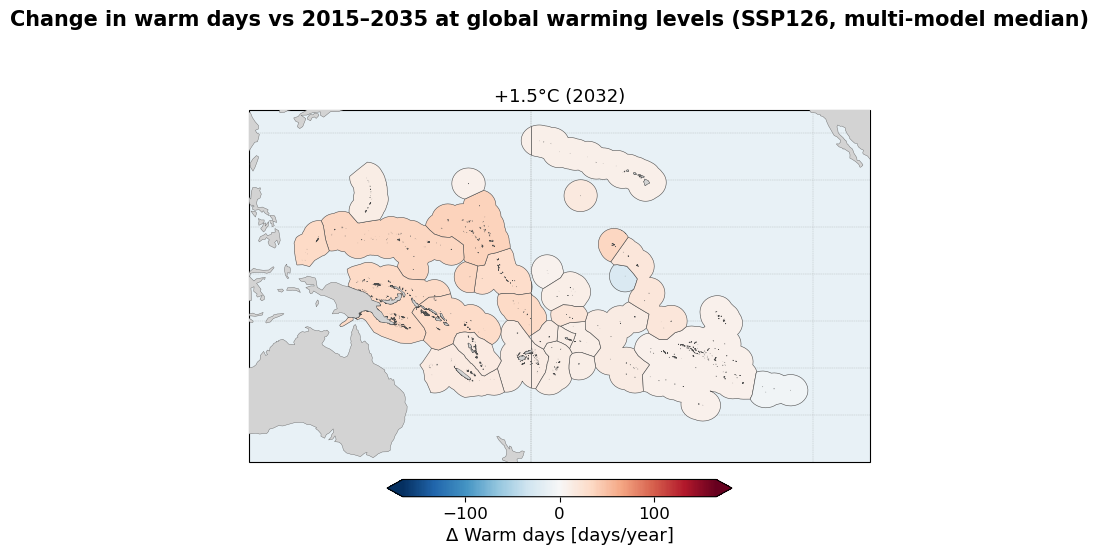

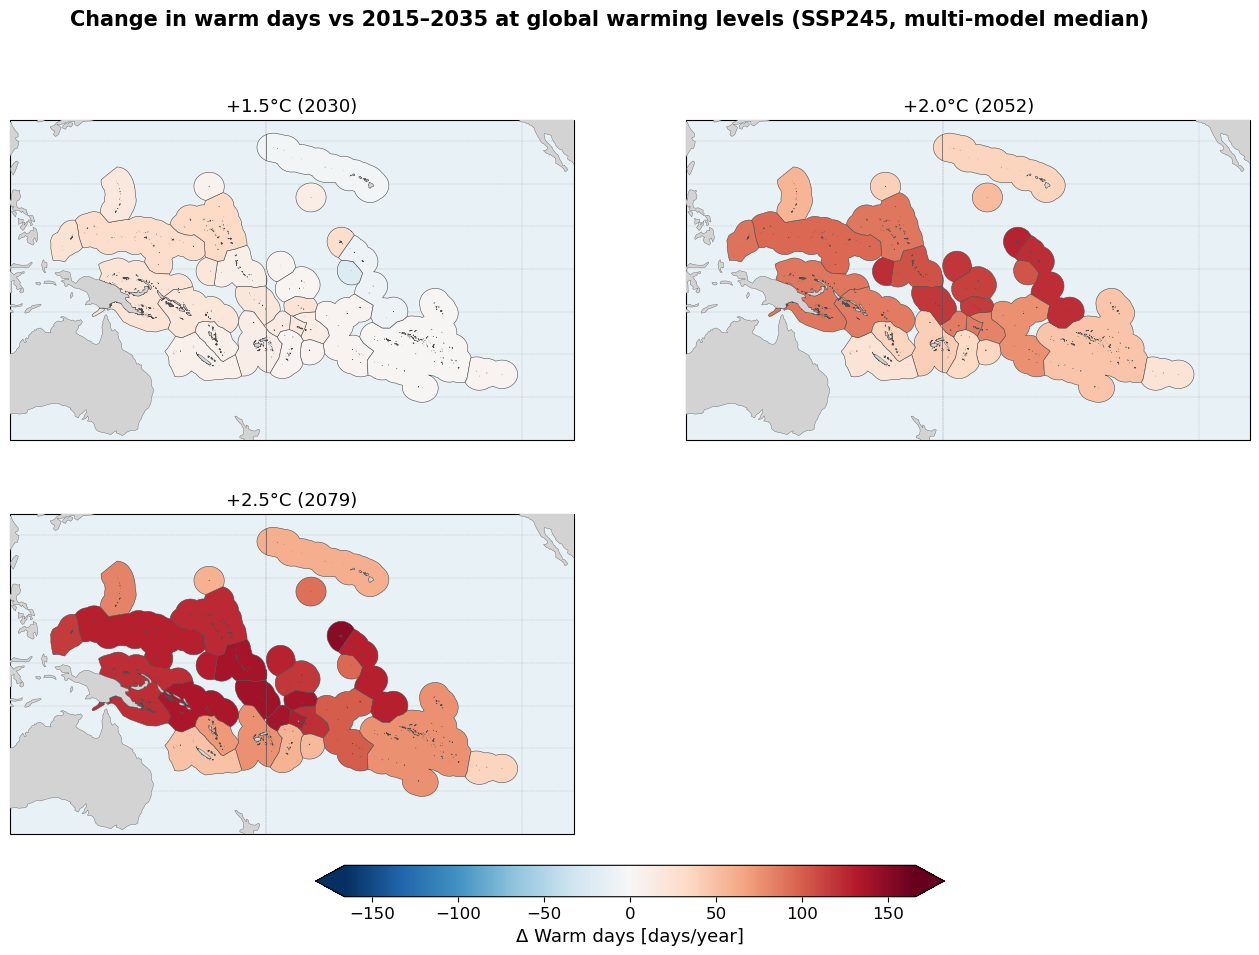

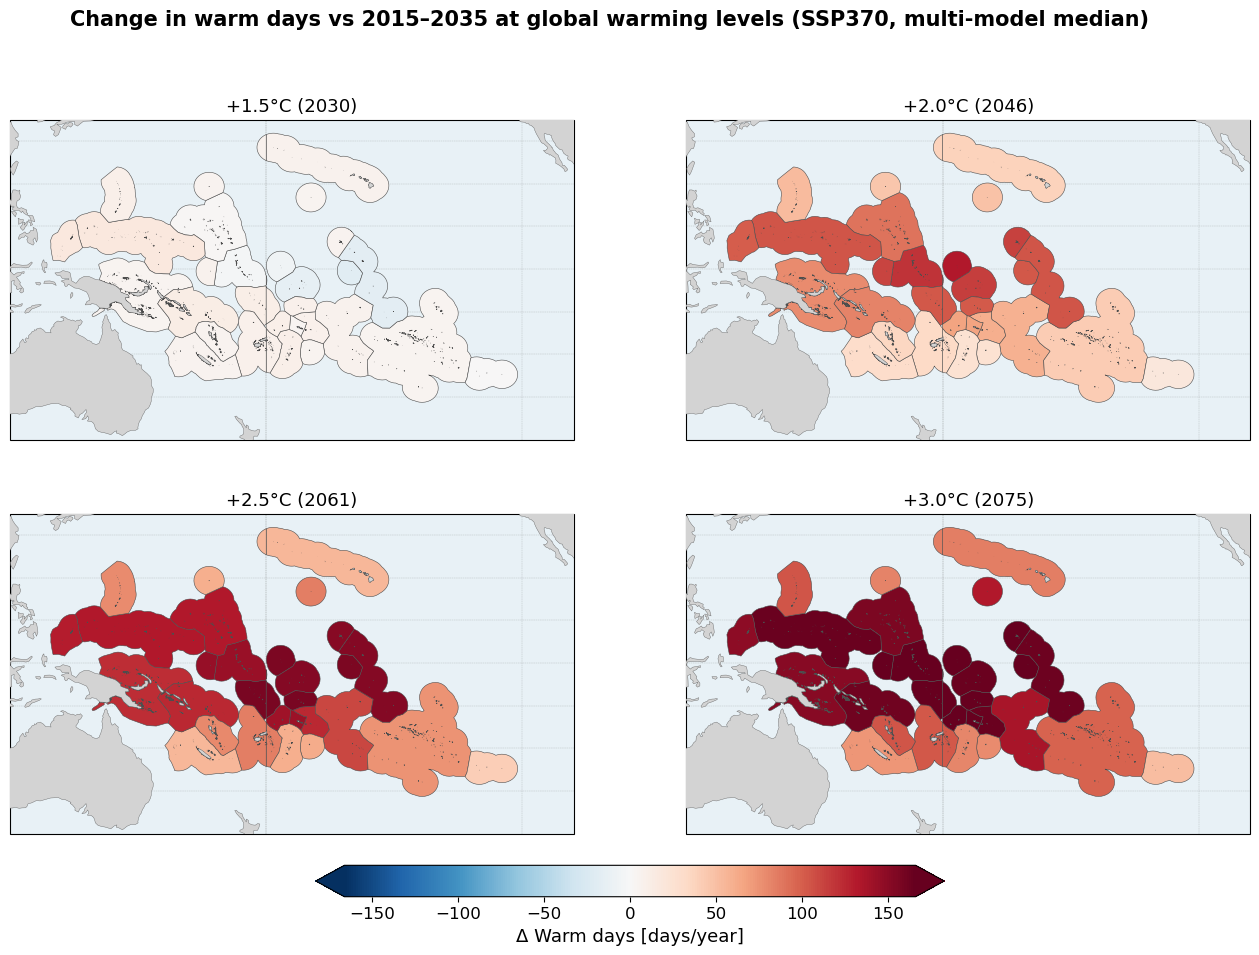

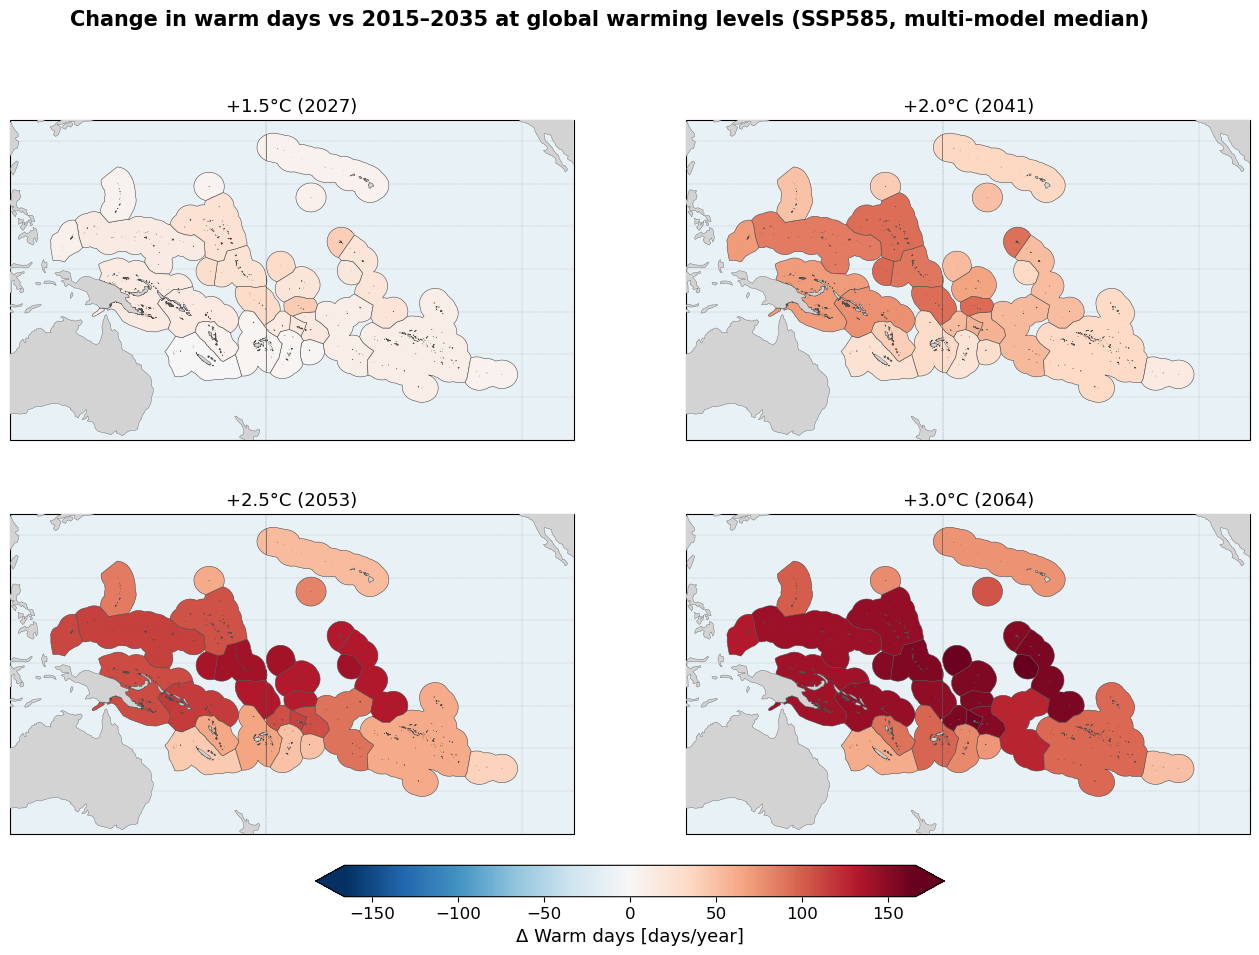

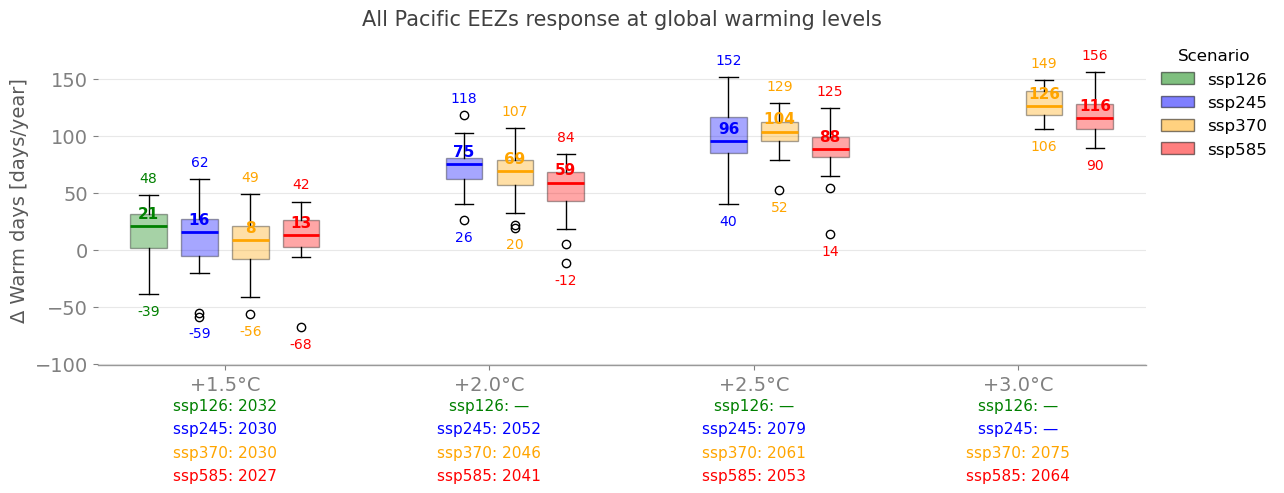

In [7]:
ds = reg.extract_regional_means("warmdays", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "warmdays", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
reg.show_tables(tables)


## Cold nights

Annual number of cold nights.

**Cold nights: linear trend 2015–2100 of the multi-model median (days/year per decade), by EEZ**

,SSP126,SSP245,SSP370,SSP585
American Samoa,-0.41,-0.73,-0.89,-0.94
Cook Islands,-0.59,-0.96,-1.33,-1.38
Fiji,-0.56,-0.94,-1.32,-1.43
French Polynesia,-0.94,-1.42,-1.84,-1.82
Hawaii,-0.75,-1.28,-1.80,-1.51
Howland Island and Baker Island,-0.40,-0.56,-0.62,-0.73
Jarvis Island,-0.72,-0.55,-0.93,-0.89
Johnston Atoll,-0.54,-0.83,-1.16,-0.96
Kiribati,-0.35,-0.58,-0.46,-0.66
Line Group,-0.42,-0.51,-0.63,-0.57


**Change in cold nights vs 2015–2035 at the global warming levels (SSP126, multi-model median, days/year), by EEZ**

,+1.5°C (2032)
region,
American Samoa,-2.4
Cook Islands,-2.0
Fiji,-4.8
French Polynesia,-2.5
Hawaii,-2.9
Howland Island and Baker Island,-3.5
Jarvis Island,-6.1
Johnston Atoll,-4.3
Kiribati,-2.6


**Change in cold nights vs 2015–2035 at the global warming levels (SSP245, multi-model median, days/year), by EEZ**

,+1.5°C (2030),+2.0°C (2052),+2.5°C (2079)
region,,,
American Samoa,-3.2,-5.5,-6.7
Cook Islands,-2.4,-6.3,-7.6
Fiji,-4.1,-6.2,-7.8
French Polynesia,-2.7,-7.1,-9.6
Hawaii,-3.2,-5.9,-7.9
Howland Island and Baker Island,-5.8,-8.0,-6.9
Jarvis Island,-5.5,-9.4,-9.4
Johnston Atoll,-2.7,-5.1,-6.9
Kiribati,-5.1,-6.4,-7.0


... (2 outputs left out)

**Change in cold nights vs 2015–2035 at the global warming levels (SSP585, multi-model median, days/year), by EEZ**

,+1.5°C (2027),+2.0°C (2041),+2.5°C (2053),+3.0°C (2064)
region,,,,
American Samoa,-1.5,-5.5,-6.0,-6.6
Cook Islands,-0.7,-5.5,-6.9,-8.2
Fiji,-1.8,-7.4,-9.0,-9.5
French Polynesia,-1.8,-7.1,-9.4,-11.4
Hawaii,-4.3,-5.4,-8.3,-10.3
Howland Island and Baker Island,-4.5,-3.1,-5.8,-6.8
Jarvis Island,-6.2,-3.0,-9.1,-9.3
Johnston Atoll,-3.0,-5.2,-6.3,-6.8
Kiribati,-3.5,-3.1,-6.4,-5.7


**Change in cold nights vs 2015–2035 at the global warming levels (days/year): spread across models in All Pacific EEZs**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,All Pacific EEZs,SSP126,+1.5°C,2032,25,-1.8,-5.8,1.9,-8.4,12.0
1,All Pacific EEZs,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,All Pacific EEZs,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,All Pacific EEZs,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,All Pacific EEZs,SSP245,+1.5°C,2030,26,-2.1,-5.7,2.3,-11.2,7.2
5,All Pacific EEZs,SSP245,+2.0°C,2052,26,-5.3,-9.5,-3.2,-12.9,-1.7
6,All Pacific EEZs,SSP245,+2.5°C,2079,26,-7.3,-11.4,-3.7,-15.1,0.7
7,All Pacific EEZs,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,All Pacific EEZs,SSP370,+1.5°C,2030,25,-3.2,-7.2,-0.3,-11.4,8.3
9,All Pacific EEZs,SSP370,+2.0°C,2046,25,-6.1,-11.3,-2.8,-20.3,-1.5


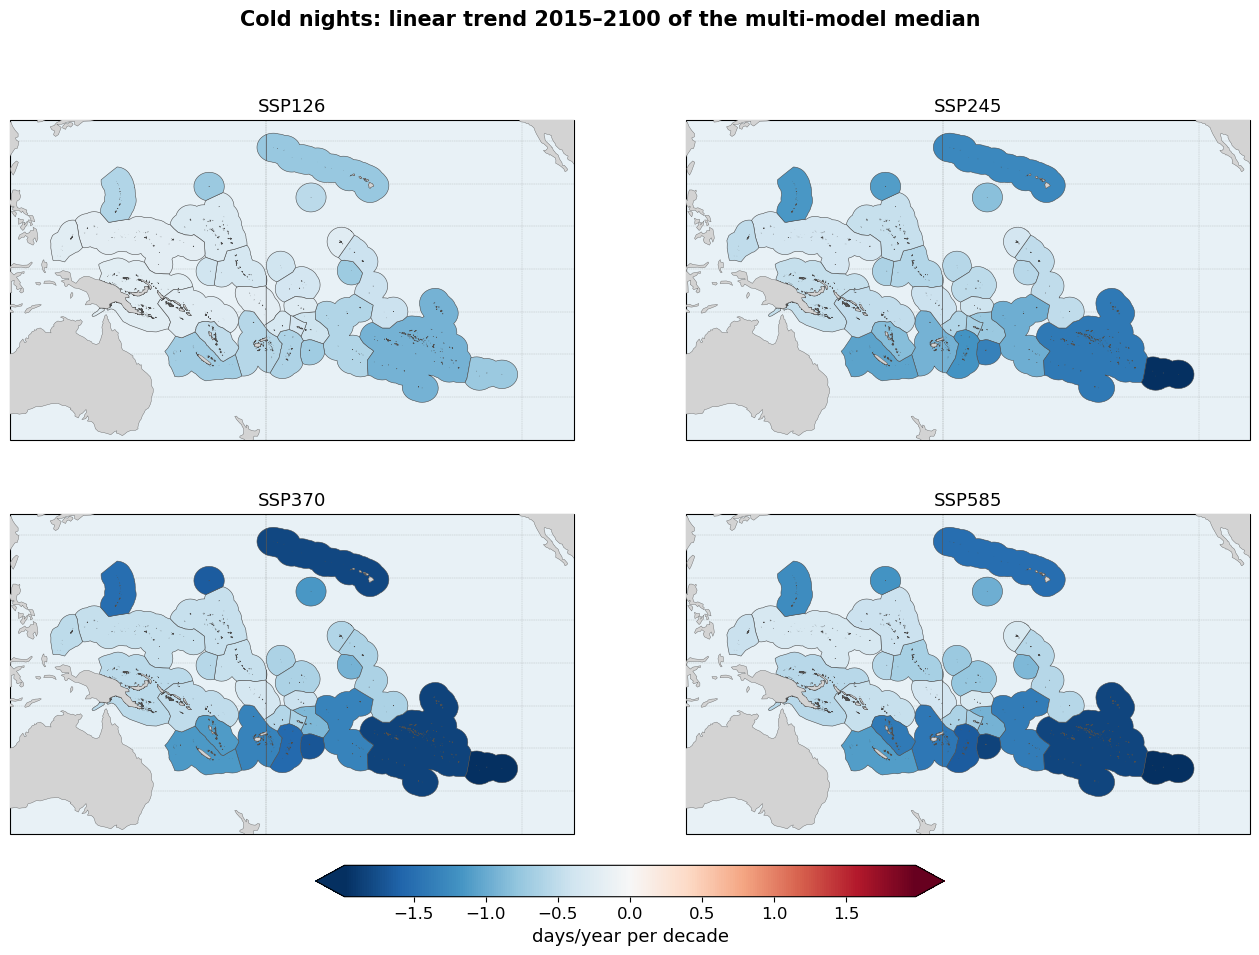

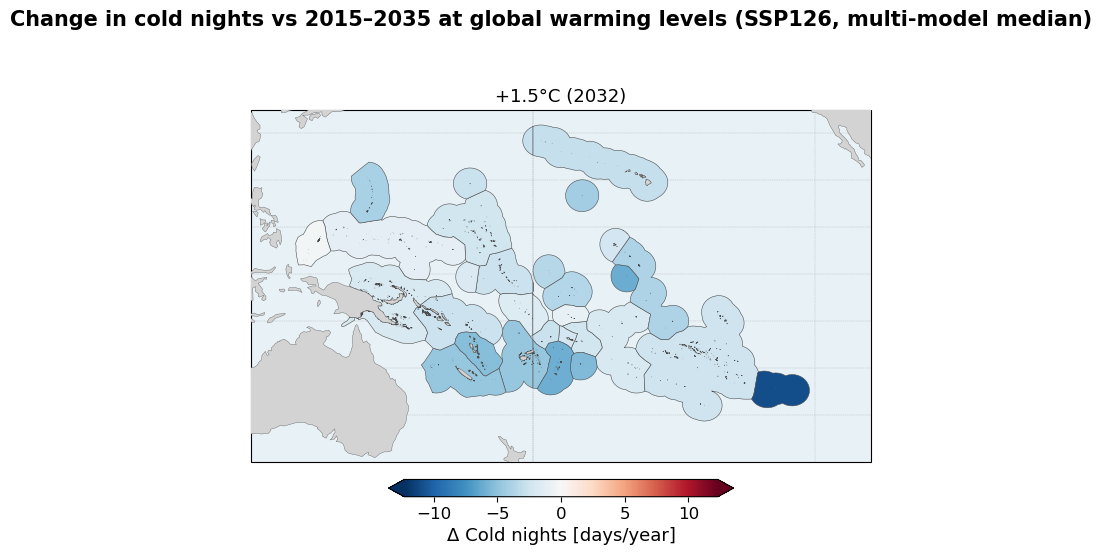

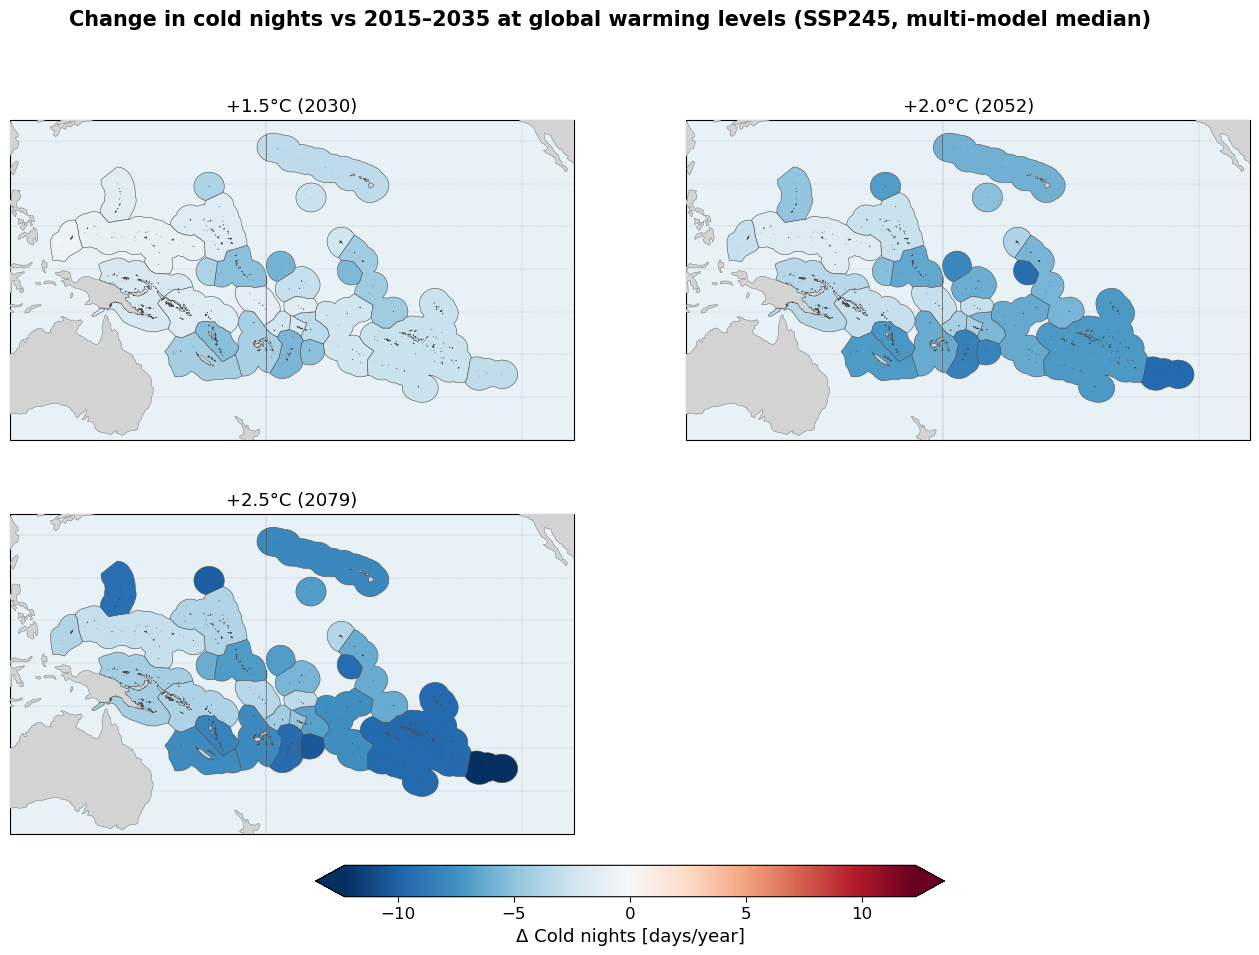

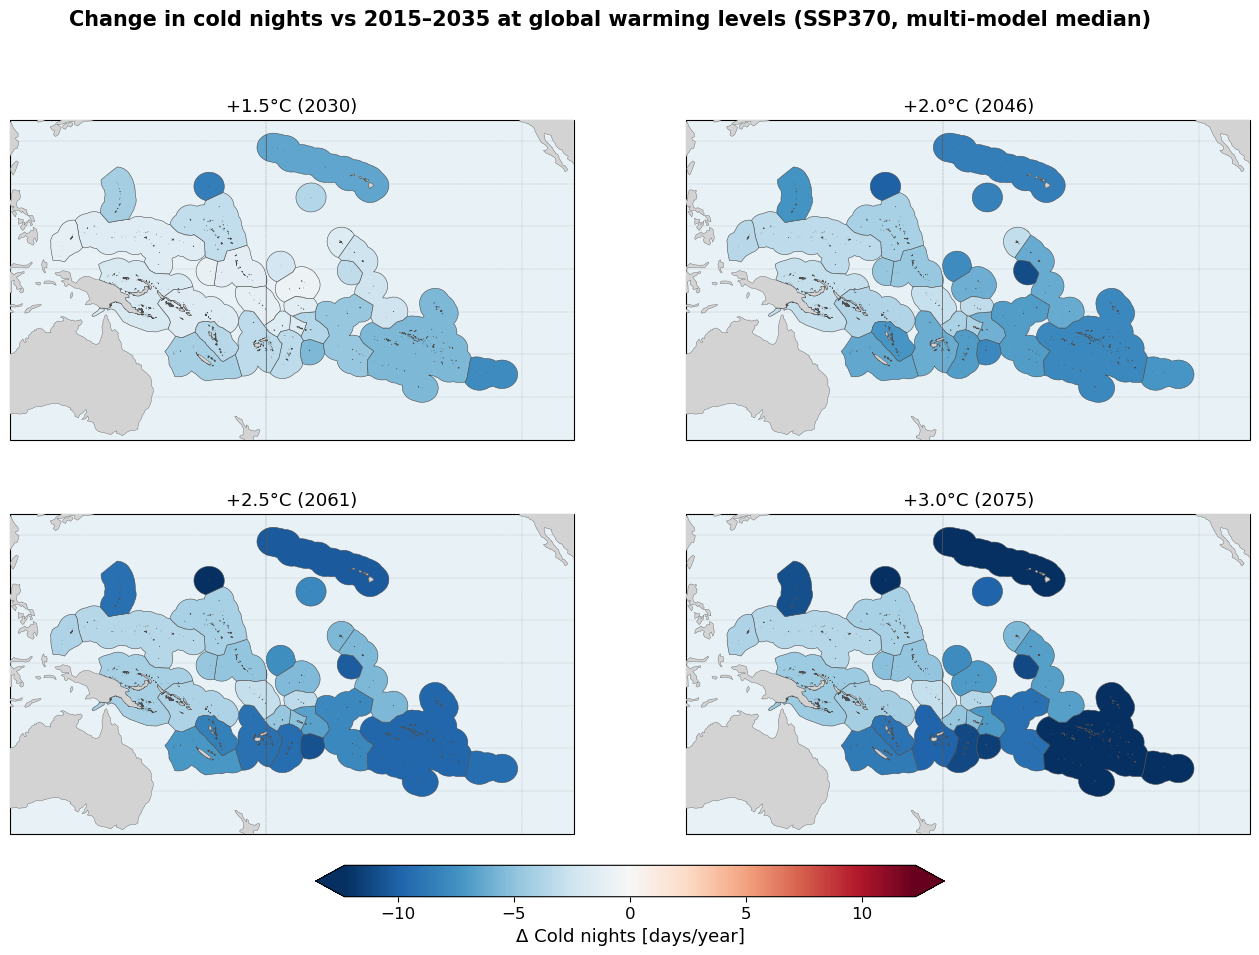

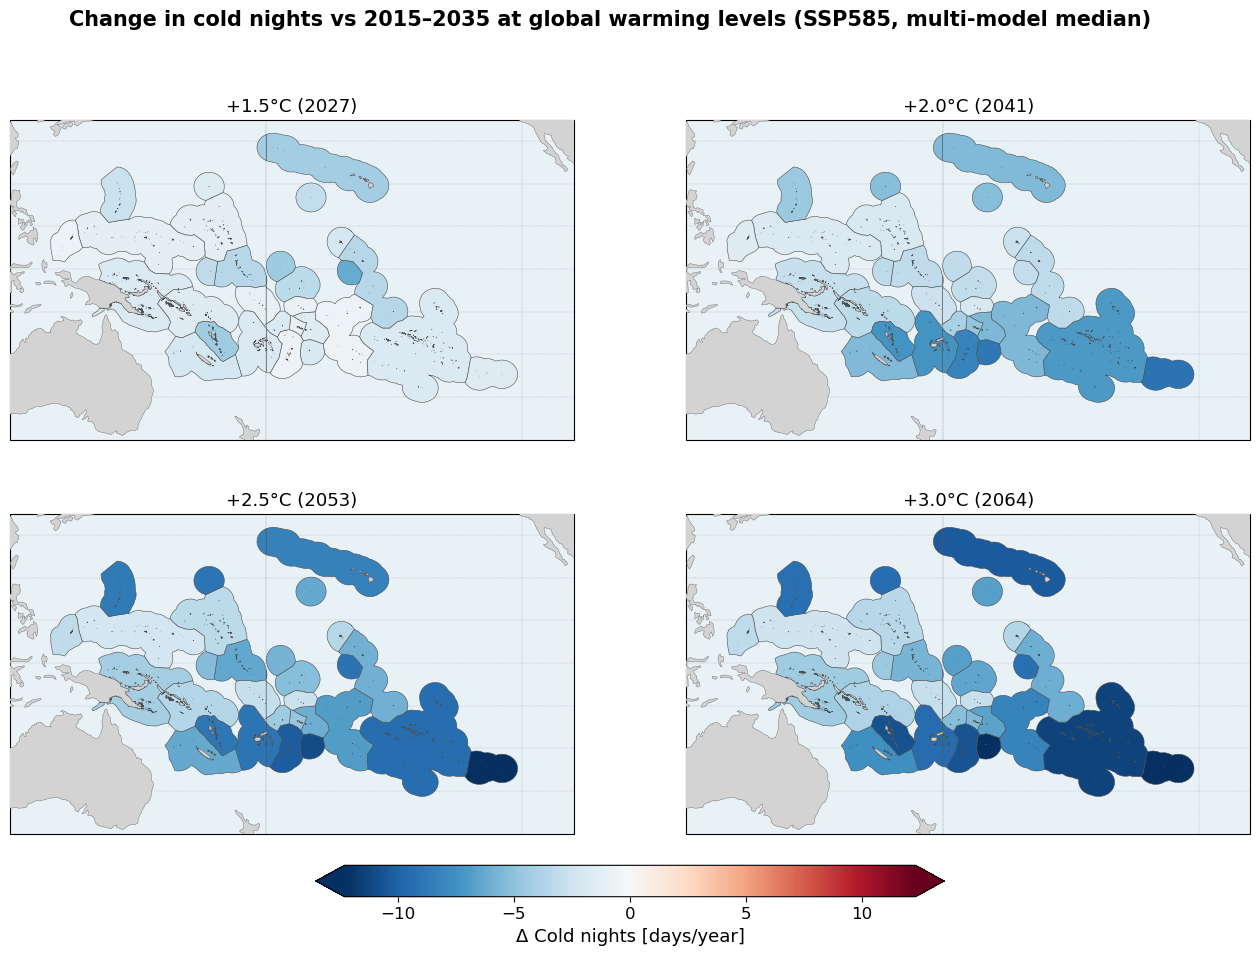

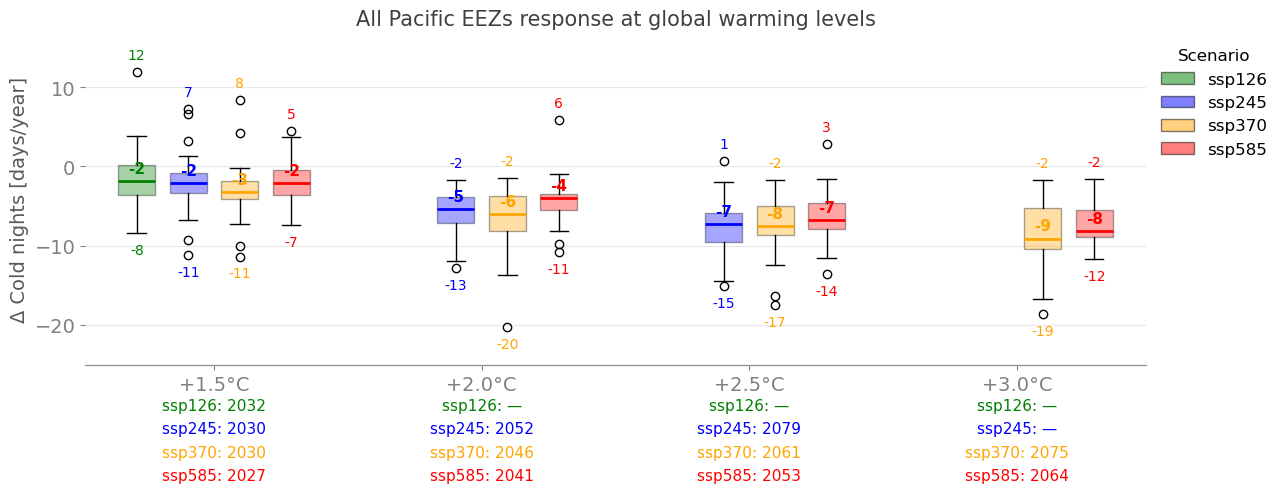

In [8]:
ds = reg.extract_regional_means("coldnights", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "coldnights", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
reg.show_tables(tables)
